# Upper limits on the KBO surface density with MAGIC + LST-1, from synthetic light curves

**Question.** A small Kuiper Belt Object (KBO) crossing the line of sight to a bright star casts a Fresnel diffraction
shadow that sweeps over the ORM in a few hundred milliseconds. How small a KBO can MAGIC-1 + MAGIC-2 + LST-1 detect,
how many hours of observation does it take to see one, and what upper limit on the KBO surface density does a null
result give?

This notebook answers it step by step with the `kbo_occultation` package, **on synthetic light curves**, so it runs
without observation data (only the optional *coloured* noise needs the noise measured on a real run, see section 3).
The chain, with the module that does each step:

| # | Step | What it shows | Module |
|---|---|---|---|
| 2 | Templates | Fresnel pattern of a KBO in front of a star of finite size, at the search cadence | `simulation.engine`, `analysis.min_size` |
| 3 | Noise | What limits a 5 ms light curve, and the synthetic noise that mimics it | `simulation.instruments`, `analysis.synthetic` |
| 4 | Search | Matched filter with a template bank, SNR trace | `analysis.mimic`, `analysis.matched_filter` |
| 5 | False alarms | Thresholds from the blind search of the *uninjected* runs | `analysis.min_size`, `analysis.synthetic` |
| 6 | Injection / recovery | Detection efficiency vs KBO radius, against the prediction | `analysis.noise_removal`, `analysis.min_size` |
| 7 | Minimum size | R50, and the detection width over impact parameters | `analysis.min_size` |
| 8 | User choices | What changes R50 | `analysis.min_size` |
| 9 | Observing time | Hours per detected event | `analysis.rates` |
| 10 | Upper limits | $N(>r)$ for a null survey, against the literature | `analysis.upper_limits` |

**Assumptions** (the same as `analysis.synthetic`): the noise is Gaussian, stationary and independent between the three
telescopes. The real noise is intermittent and non-Gaussian, so real-data numbers are somewhat different
(`min_size.SNR_CALIBRATION`). The channels are C = MAGIC-1, A = MAGIC-2, B = LST-1.

**How to run.** Set the parameters in section 1. With `FAST = True` the first run takes about 25-30 minutes: the injections of section 5 (~6 min) and
the detection widths of section 7 (~13 min) dominate. Both are cached as CSV files in `outputs/notebooks/synthetic_upper_limits/`,
so a re-run takes about 5 minutes. Changing a parameter that affects the injections (trials, radii, run length, seed, bank)
changes the cache name, so old results are never reused by mistake.

In [1]:
import os
import time
import warnings
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u

from kbo_occultation.analysis import min_size as ms
from kbo_occultation.analysis import rates
from kbo_occultation.analysis import synthetic as sy
from kbo_occultation.analysis.mimic import (MimicConfig, _template_duration, bin_lightcurve, observed_star_mas, star_bank)
from kbo_occultation.analysis.matched_filter import compute_baseline_and_sigma, sliding_matched_filter_snr
from kbo_occultation.analysis.injection import inject_occultation
from kbo_occultation.analysis.noise_removal import ComparisonConfig, build_methods, reshaped_templates, shadow_offsets_s
from kbo_occultation.analysis.upper_limits import EfficiencyCurve, SurveyExposure, cumulative_density_upper_limit, fresnel_scale_m
from kbo_occultation.observations.photometry import LightCurve
from kbo_occultation.simulation.instruments import Instrument
from kbo_occultation.simulation.kinematics import EARTH_SEMIMAJOR_AXIS_AU, shadow_velocity_opposition
from kbo_occultation.simulation.physics import AU_m, mas_to_rad, star_radius_from_mag

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()      # repository root

## 1. User parameters

Everything you may want to change is in the next cell. The comments say what each choice does; section 8 measures how
much the main ones move the result.

In [2]:
# ── how much to compute ─────────────────────────────────────────────────────────────────────────────────────────────
FAST = True                         # True: small injection campaign (minutes); False: larger one (hours)
SEED = 0

# ── synthetic stars and noise ───────────────────────────────────────────────────────────────────────────────────────
MAGS = (7.0, 8.0, 9.0)              # Johnson B magnitudes (Vega) of the synthetic stars; angular radius follows B
MAG_MID = MAGS[len(MAGS) // 2]      # the star shown in the single-run plots and used as the baseline of section 8
NOISE_MODELS = ("white", "coloured")  # white: noise-model level only; coloured: + excess PSD measured on a real run
RUN_S = 600.0                       # length of a synthetic run [s]; longer = better false-alarm tails, slower
N_RUNS_PER_MAG = 1 if FAST else 2   # independent noise draws per magnitude
PROFILES = ROOT / "outputs" / "min_size" / "profiles_2026-03-08_2026-08-19.npz"   # measured noise profiles (npz)
PROFILE_NIGHTS = ("2026-03-08", "2026-08-19")   # nights measured if PROFILES does not exist (3-channel nights)
MEASURE_PROFILES = True             # measure PROFILES from the logged runs when the file is missing (slow, needs data)
REFERENCE = "median"                # real run whose conditions / excess the synthetic runs copy: median | all | NIGHT/OBS

# ── injections and search ───────────────────────────────────────────────────────────────────────────────────────────
N_TRIALS = 15 if FAST else 40       # injections per run, channel and radius
RADII = np.round(np.geomspace(20.0, 200.0, 8 if FAST else 12), 1)    # KBO radii [m] of the injections
CORRECTIONS = ("whitened",) if FAST else ("whitened", "butter_1", "raw")   # noise corrections applied before the search
PER_STAR_BANK = True                # search templates of each star's own size (True) or the fixed 0.03 mas bank (False)
FARS = (1.0, 0.1, 0.01)             # coincidence false-alarm rates [1/h]; the first is the headline
MIN_NTEL = 2                        # telescopes that must agree (2 of 3)

# ── geometry and size distribution ──────────────────────────────────────────────────────────────────────────────────
DISTANCE_AU = 39.0                  # KBO distance from the Earth at opposition
D_BREAK_KM = 80.0                   # break diameter of the size distribution (Nihei et al. 2007)
Q_S = (2.0, 3.0, 4.0)               # small-object slopes of the size distribution
Q_S_HEADLINE = 4.0
SURVEY_HOURS = (10.0, 50.0, 100.0)    # on-target hours of the survey scenarios of section 10

cfg = ms.MinSizeConfig(time_resolved=False, distance_au=DISTANCE_AU, correction=CORRECTIONS[0],
                       coinc_far_per_hr=FARS[0], extra_fars=tuple(FARS[1:]), min_ntel=MIN_NTEL)
ccfg = ComparisonConfig(mimic=MimicConfig(per_star_size=PER_STAR_BANK), n_trials=N_TRIALS, seed=SEED)
TOL = cfg.tolerance_s()
V_SHADOW = cfg.velocity_mps()
D_BREAK = D_BREAK_KM * u.km

OUT = ROOT / "outputs" / "notebooks" / "synthetic_upper_limits"
(OUT / "trials").mkdir(parents=True, exist_ok=True)
print(f"shadow velocity {V_SHADOW / 1e3:.1f} km/s, coincidence window {TOL * 1e3:.1f} ms, bin {cfg.bin_dt_s * 1e3:.2f} ms")
print(f"outputs in {OUT}")

shadow velocity 25.1 km/s, coincidence window 404.7 ms, bin 5.24 ms
outputs in /home/elia-dell/Projects/Python/kbo_occultation/outputs/notebooks/synthetic_upper_limits


In [3]:
# plotting helpers (same muted style as examples/studies)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
TEL_NAME = {"C": "MAGIC-1", "A": "MAGIC-2", "B": "LST-1"}
TEL_COLOR = {"C": "#2a78d6", "A": "#1baf7a", "B": "#8a5cd0"}
NOISE_COLOR = {"white": "#2a78d6", "coloured": "#eb6834"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 140, "axes.titlesize": 10, "axes.labelsize": 9})

def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    return ax

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()

def binomial_err(hits, n):
    p = np.clip(hits / n, 0.5 / n, 1.0 - 0.5 / n)
    return np.sqrt(p * (1.0 - p) / n)

def read_csv_or_empty(path):
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()

def cat(frames):
    frames = [f for f in frames if len(f)]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

## 2. Targets and templates

**The star.** The diffraction pattern of a KBO of radius $R$ at distance $d$ depends on the Fresnel scale
$F=\sqrt{\lambda d/2}$ (about 1.1 km at 420 nm and 39 AU) and on the size of the stellar disk projected at the KBO's
distance. The package assumes stars of fixed surface brightness, so the angular radius follows the magnitude,
$\theta_\star = 0.03\,\mathrm{mas}\cdot10^{-0.2(B-7)}$ (`physics.star_radius_from_mag`). A B = 7 star projects to about
0.85 km, which already smears the fringes; fainter stars are smaller and give sharper fringes but fewer photons.

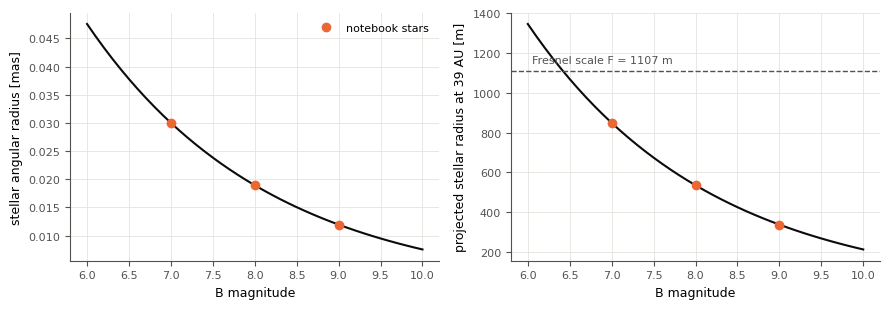

In [4]:
mags_fine = np.linspace(6.0, 10.0, 41)
theta_mas = np.array([star_radius_from_mag(m) for m in mags_fine])
r_proj_m = theta_mas * mas_to_rad * cfg.distance_au * AU_m                       # projected at the KBO
F_m = fresnel_scale_m(ms.WIDTH_WAVELENGTH_M, cfg.distance_au)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, y, label in ((axes[0], theta_mas, "stellar angular radius [mas]"),
                     (axes[1], r_proj_m, f"projected stellar radius at {cfg.distance_au:g} AU [m]")):
    style(ax)
    ax.plot(mags_fine, y, color=INK)
    ax.plot(MAGS, np.interp(MAGS, mags_fine, y), "o", color=NOISE_COLOR["coloured"], label="notebook stars")
    ax.set_xlabel("B magnitude")
    ax.set_ylabel(label)
axes[1].axhline(F_m, color=MUTED, ls="--", lw=1)
axes[1].text(6.05, F_m * 1.04, f"Fresnel scale F = {F_m:.0f} m", color=MUTED, fontsize=8)
axes[0].legend(frameon=False, fontsize=8)
finish(fig, "01_star_size")

**The pattern in space.** `ms.injection_patterns` evaluates the polychromatic Fresnel pattern through the response of a
telescope (atmosphere × mirror × QE × camera, `Instrument.response`), with the finite stellar disk. Below, the pattern of
a star with B = 8 for several KBO radii (left), and the effect of the star's size at fixed $R = 100$ m (right). Small
objects ($R \ll F$) all have a similar, diffraction-limited width: the dip gets *shallower* with $R$, not narrower.

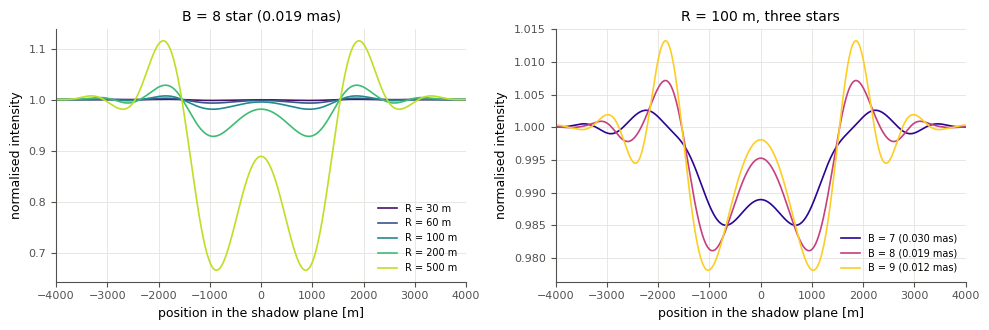

LST vs MAGIC pattern, R = 100 m: max |ΔI| = 2.4e-13 (they share their QE and reflectivity curves, so the shape is the same; only the photon counts differ)


In [7]:
INSTR = {kind: Instrument(kind, filter_type=cfg.filter_type, site="LaPalma") for kind in ("MAGIC", "LST")}
star8 = ms.generic_targets([8.0])[0]
radii_show = [30.0, 60.0, 100.0, 200.0, 500.0]
pat = ms.injection_patterns(star8, cfg, INSTR["MAGIC"], radii_show)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
style(axes[0])
for r, c in zip(radii_show, plt.cm.viridis(np.linspace(0.05, 0.9, len(radii_show)))):
    x, i = pat[r]
    axes[0].plot(x, i, color=c, lw=1.2, label=f"R = {r:g} m")
axes[0].set_title(f"B = 8 star ({star8.angular_radius_mas:.3f} mas)")
axes[0].legend(frameon=False, fontsize=7, loc="lower right")
style(axes[1])
for mag, c in zip(MAGS, plt.cm.plasma(np.linspace(0.05, 0.9, len(MAGS)))):
    s = ms.generic_targets([mag])[0]
    x, i = ms.injection_patterns(s, cfg, INSTR["MAGIC"], [100.0])[100.0]
    axes[1].plot(x, i, color=c, lw=1.2, label=f"B = {mag:g} ({s.angular_radius_mas:.3f} mas)")
axes[1].set_title("R = 100 m, three stars")
axes[1].legend(frameon=False, fontsize=7, loc="lower right")
for ax in axes:
    ax.set_xlim(-4000, 4000)
    ax.set_xlabel("position in the shadow plane [m]")
axes[0].set_ylabel("normalised intensity")
axes[1].set_ylabel("normalised intensity")
finish(fig, "02_fresnel_patterns")

x_l, i_l = ms.injection_patterns(star8, cfg, INSTR["LST"], [100.0])[100.0]
print(f"LST vs MAGIC pattern, R = 100 m: max |ΔI| = {np.max(np.abs(i_l - pat[100.0][1])):.1e} "
      "(they share their QE and reflectivity curves, so the shape is the same; only the photon counts differ)")

**The template at the search cadence.** The search works on light curves binned to 10 frames (5.24 ms), and the shadow
crosses a point at $v \approx 25$ km/s, so the pattern becomes a ~0.2-0.5 s signal, in the 0.2-25 Hz band
(`analysis.bands.SIGNAL_BAND_HZ`). `ms.template_family` gives $I-1$ for each radius on that grid. Below, the templates
for a bright (B = 7) and a faint (B = 9) star.

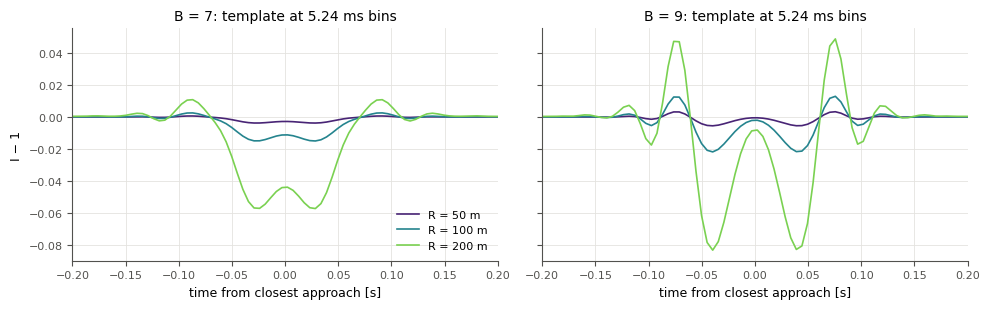

In [12]:
radii_t = np.array([50.0, 100.0, 200.0])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, mag in zip(axes, (7.0, 9.0)):
    style(ax)
    star = ms.generic_targets([mag])[0]
    fam = ms.template_family(star, replace(cfg, radii_m=radii_t), INSTR["MAGIC"])
    for r, c in zip(radii_t, plt.cm.viridis([0.1, 0.45, 0.8])):
        n = len(fam[r])
        t = -cfg.x_half_m / V_SHADOW + (np.arange(n) + 0.5) * cfg.bin_dt_s
        ax.plot(t, fam[r], color=c, lw=1.2, label=f"R = {r:g} m")
    ax.set_title(f"B = {mag:g}: template at {cfg.bin_dt_s * 1e3:.2f} ms bins")
    ax.set_xlim(-0.2, 0.2)
    ax.set_xlabel("time from closest approach [s]")
axes[0].set_ylabel("I − 1")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
finish(fig, "03_templates")

**The search bank.** The KBO's radius is unknown, so the search slides a *bank* of templates (30, 60, 100 and 200 m)
over the light curve and keeps the best. The star's size is known, so by default the bank is built for the star
being observed (`mimic.star_bank`; `PER_STAR_BANK = False` uses the fixed 0.03 mas star of the older search). A bank
built for a bigger star than the real one fits a small star's sharper fringes badly. The right panel gives the fraction
of the ideal (perfectly matched template, white noise) SNR the bank keeps.

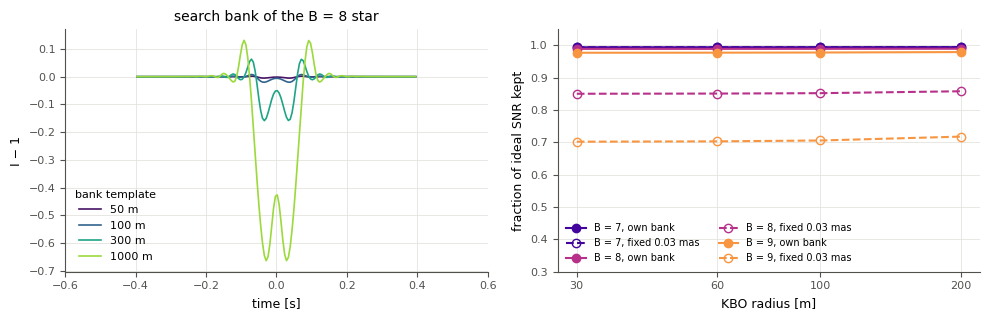

In [ ]:
_FAMILIES = {}

def family_of(star, cfg_v, radii):
    # {R: I - 1} at the bin cadence of ``star`` (ms.template_family), computed once per star and geometry. MAGIC and
    # LST have the same pattern shape (section 2), so one family serves every telescope; their photon counts enter
    # the noise, not the template.
    key = (star, tuple(float(r) for r in radii), cfg_v.distance_au, cfg_v.filter_type, cfg_v.x_half_m, cfg_v.bin_samples)
    if key not in _FAMILIES:
        _FAMILIES[key] = ms.template_family(star, replace(cfg_v, radii_m=np.asarray(radii, float)),
                                            Instrument("MAGIC", filter_type=cfg_v.filter_type, site="LaPalma"))
    return _FAMILIES[key]


star_of = {mag: ms.generic_targets([mag])[0] for mag in MAGS}
bank_own = {mag: ms.bank_deltas(cfg, star=star_of[mag]) for mag in MAGS}
bank_fixed = ms.bank_deltas(cfg)

n_fft = 1024
freq_w = np.fft.rfftfreq(n_fft, cfg.bin_dt_s)
psd_w, fs_bin = np.ones_like(freq_w), 1.0 / cfg.bin_dt_s
radii_k = np.array([30.0, 60.0, 100.0, 200.0])


def kept_fraction(star, bank):
    fam = family_of(star, cfg, radii_k)
    return np.array([ms.bank_snr(fam[r], bank, freq_w, psd_w, fs_bin) / ms.expected_snr(fam[r], freq_w, psd_w, fs_bin)
                     for r in radii_k])


fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
style(axes[0])
n = len(next(iter(bank_own[MAG_MID].values())))
t = -cfg.x_half_m / V_SHADOW + (np.arange(n) + 0.5) * cfg.bin_dt_s
for (r, tpl), c in zip(bank_own[MAG_MID].items(), plt.cm.viridis(np.linspace(0.05, 0.85, 4))):
    axes[0].plot(t, tpl, color=c, lw=1.2, label=f"{r:g} m")
axes[0].set_xlim(-0.4, 0.4)
axes[0].set_xlabel("time [s]")
axes[0].set_ylabel("I − 1")
axes[0].set_title(f"search bank of the B = {MAG_MID:g} star")
axes[0].legend(frameon=False, fontsize=8, title="bank template", title_fontsize=8)
style(axes[1])
for mag, c in zip(MAGS, plt.cm.plasma(np.linspace(0.1, 0.75, len(MAGS)))):
    axes[1].plot(radii_k, kept_fraction(star_of[mag], bank_own[mag]), "o-", color=c, label=f"B = {mag:g}, own bank")
    axes[1].plot(radii_k, kept_fraction(star_of[mag], bank_fixed), "o--", color=c, mfc="none", label=f"B = {mag:g}, fixed 0.03 mas")
axes[1].set_xscale("log")
axes[1].set_xticks(radii_k)
axes[1].set_xticklabels([f"{r:g}" for r in radii_k])
axes[1].minorticks_off()
axes[1].set_xlabel("KBO radius [m]")
axes[1].set_ylabel("fraction of ideal SNR kept")
axes[1].set_ylim(0.3, 1.05)
axes[1].legend(frameon=False, fontsize=7, ncol=2)
finish(fig, "04_search_bank")

## 3. Noise

### 3a. The white noise level of the model

`Instrument.noise_budget` gives the fractional noise of a bin (noise / star signal) as the quadrature sum of

* **shot noise** of the star + night-sky background (NSB), inflated by the photomultiplier's excess-noise factor;
* **scintillation** of the atmosphere (independent of the star's brightness, so it dominates for bright stars);
* the **variance-estimator floor**: the DAQ's flux proxy is the variance of $2^{18}$ samples per frame, which has a
  relative error $\sqrt{2k/N}\approx0.4\%$ per frame, averaged down over the 10 frames of a bin.

This is the *white* part of the noise, and it is all that the "theory only" curves of the package contain.

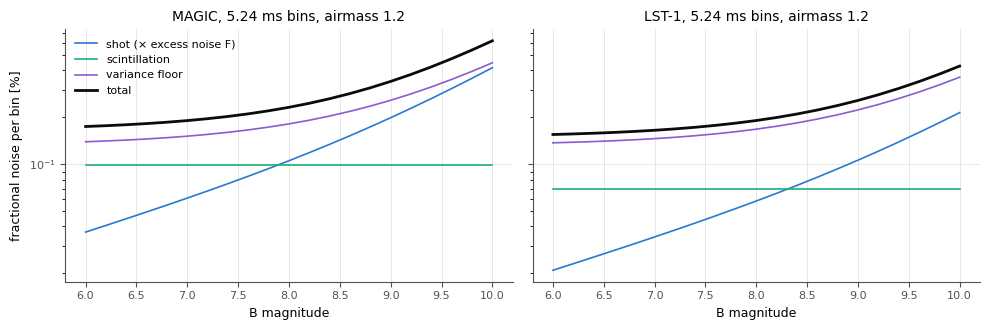

In [8]:
mags_n = np.linspace(6.0, 10.0, 21)
dt_bin = cfg.bin_dt_s * u.s
terms = {"sigma_shot": "shot (× excess noise F)", "sigma_scint": "scintillation", "sigma_floor": "variance floor",
         "sigma_total": "total"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, kind, name in zip(axes, ("MAGIC", "LST"), ("MAGIC", "LST-1")):
    style(ax)
    budget = [INSTR[kind].noise_budget(m, dt_bin, airmass=cfg.airmass, extinction=True) for m in mags_n]
    for key, c in zip(terms, ("#2a78d6", "#1baf7a", "#8a5cd0", INK)):
        ax.plot(mags_n, [100 * b[key] for b in budget], color=c, lw=2 if key == "sigma_total" else 1.2, label=terms[key])
    ax.set_yscale("log")
    ax.set_title(f"{name}, {cfg.bin_dt_s * 1e3:.2f} ms bins, airmass {cfg.airmass:g}")
    ax.set_xlabel("B magnitude")
axes[0].set_ylabel("fractional noise per bin [%]")
axes[0].legend(frameon=False, fontsize=8)
finish(fig, "05_noise_budget")

### 3b. Noise profiles measured on real runs, and why the excess is added on top of the white noise

Real light curves are noisier than the model, and the extra noise is **not white**: wind, tracking, and transparency
changes put correlated noise between ~0.1 and a few Hz, right in the band of the diffraction signal. Binning or
adding telescopes does not average it down. This is what roughly doubles the minimum detectable size with respect to
the ideal system (`theory only` in the package's tables).

The package keeps that extra noise as an **excess PSD**. For each real run and telescope (`ms.NoiseProfile`,
`ms.measure_noise_profiles`):

$$S_\mathrm{excess}(f) = \max\!\Big[\,\frac{S_\mathrm{measured}(f)}{f_\star^{\,2}} - S_\mathrm{white}^\mathrm{model}\,,\ 0\Big],$$

where $S_\mathrm{measured}$ is the PSD of the run's fractional flux, $f_\star=S/(S+\mathrm{NSB})$ the star's share of the
light (the PSD is converted to *star units*, the fractional noise of the star alone), and $S^\mathrm{model}_\mathrm{white}$
the white level of `noise_budget` for that run's star under that run's conditions (airmass, mirror throughput, PSF).

To get the noise of **another** star under the same conditions, `ms.noise_psd` adds the excess to *that star's own*
white level:

$$S(f) = S_\mathrm{white}(B_\mathrm{target}) + S_\mathrm{excess}(f).$$

The white part is what scales with magnitude (shot noise grows as the star dims); the excess is taken as fixed in star
units (`excess_scaling="star"`; `"total"` fixes it in total-signal units instead, see section 8). The white level has
to be taken *out* before the excess is stored; otherwise it would be counted twice when the target's own level is added.

The profiles are the only place the synthetic pipeline needs real data. They are loaded from `PROFILES` if that file
exists, otherwise measured from the logged runs (`MEASURE_PROFILES`; this loads the light curves, so it is slow, and
the result is saved to `PROFILES` for the next time). Without real data, only the white model is used.

In [9]:
profiles = None
if PROFILES.exists():
    profiles = ms.load_profiles(str(PROFILES))
    print(f"{len(profiles)} noise profiles loaded from {PROFILES.relative_to(ROOT)}")
elif MEASURE_PROFILES:
    try:
        from kbo_occultation.observations.log import load_observation_log
        profiles = ms.load_or_measure_profiles(load_observation_log(), list(PROFILE_NIGHTS), cfg, path=str(PROFILES),
                                               progress=print)
    except Exception as exc:                                  # no data on this machine
        print(f"could not measure the noise profiles ({type(exc).__name__}: {exc})")
if profiles is None:
    NOISE_MODELS = tuple(m for m in NOISE_MODELS if m != "coloured")
    print("no noise profiles: only the white noise model is used (conditions: airmass "
          f"{cfg.airmass:g}, throughput 1, PSF containment 1)")
else:
    refs = sy.reference_runs(profiles, REFERENCE)
    print("reference run(s):", ", ".join(f"{g['A'].night}/{g['A'].observation} (B = {g['A'].mag_B:.2f})" for g in refs))
print("noise models:", NOISE_MODELS)

21 noise profiles loaded from outputs/min_size/profiles_2026-03-08_2026-08-19.npz
reference run(s): 2026-08-19/HD199102 (B = 8.00)
noise models: ('white', 'coloured')


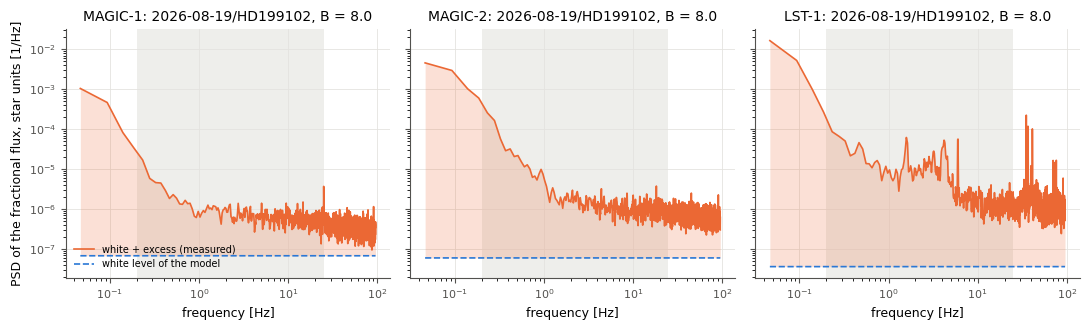

In [10]:
from kbo_occultation.analysis.bands import SIGNAL_BAND_HZ

if profiles is not None:
    ref = refs[0]
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for ax, ch in zip(axes, ("C", "A", "B")):
        p = ref[ch]
        tgt = ms.TargetStar("reference", p.mag_B, 0.03, p.teff_K or 10000.0)
        white = ms.noise_psd(p, tgt, cfg, theory_only=True)
        style(ax)
        ax.axvspan(*SIGNAL_BAND_HZ, color=GRID, alpha=0.6, lw=0)
        ax.plot(p.freq[1:], (white + p.S_excess)[1:], color=NOISE_COLOR["coloured"], lw=1.2, label="white + excess (measured)")
        ax.plot(p.freq[1:], white[1:], color=NOISE_COLOR["white"], ls="--", lw=1.2, label="white level of the model")
        ax.fill_between(p.freq[1:], white[1:], (white + p.S_excess)[1:], color=NOISE_COLOR["coloured"], alpha=0.2, lw=0)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"{TEL_NAME[ch]}: {p.night}/{p.observation}, B = {p.mag_B:.1f}")
        ax.set_xlabel("frequency [Hz]")
    axes[0].set_ylabel("PSD of the fractional flux, star units [1/Hz]")
    axes[0].legend(frameon=False, fontsize=7, loc="lower left")
    finish(fig, "06_noise_profile_reference")

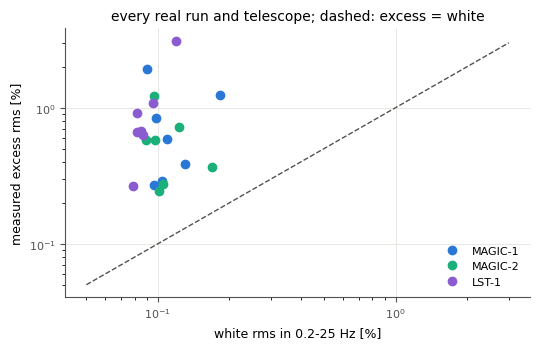

fraction of the signal band where the measured PSD is below the model's white level (excess clipped to 0): median 0.00
 group  slope  slope_err  n
pooled  -2.31       0.99 21
 MAGIC  -0.77       1.74 14
   LST  -3.33       0.77  7


In [11]:
if profiles is not None:
    lo, hi = SIGNAL_BAND_HZ
    rows = []
    for p in profiles:
        band = (p.freq >= lo) & (p.freq <= min(hi, p.freq[-1]))
        white = ms.noise_psd(p, ms.TargetStar("x", p.mag_B, 0.03, p.teff_K or 10000.0), cfg, theory_only=True)[0]
        rows.append({"night": p.night, "obs": p.observation, "channel": p.channel, "B": p.mag_B, "star_fraction": p.star_fraction,
                     "rms_white_%": 100 * np.sqrt(white * (hi - lo)), "rms_excess_%": 100 * np.sqrt(np.trapz(p.S_excess[band], p.freq[band])),
                     "clipped": p.clipped_fraction})
    prof_tab = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    style(ax)
    for ch in ("C", "A", "B"):
        g = prof_tab[prof_tab["channel"] == ch]
        ax.plot(g["rms_white_%"], g["rms_excess_%"], "o", color=TEL_COLOR[ch], label=TEL_NAME[ch])
    lim = [0.05, 3]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"white rms in {lo:g}-{hi:g} Hz [%]")
    ax.set_ylabel("measured excess rms [%]")
    ax.set_title("every real run and telescope; dashed: excess = white")
    ax.legend(frameon=False, fontsize=8)
    finish(fig, "07_excess_vs_white")
    print(f"fraction of the signal band where the measured PSD is below the model's white level (excess clipped to 0): "
          f"median {prof_tab['clipped'].median():.2f}")
    try:
        print(ms.excess_scaling_test(profiles).round(2).to_string(index=False))
    except Exception as exc:
        print("excess_scaling_test:", exc)

### 3c. The synthetic runs

`sy.synthetic_runs` makes `N_RUNS_PER_MAG` runs per magnitude. Each is three independent Gaussian light curves at the
frame cadence (0.52 ms), drawn from the PSD that `ms.noise_psd` gives for the star:

* `white`: white level only, in the conditions of the reference run (or the defaults without profiles);
* `coloured`: white level + the reference run's excess PSD, exactly what the predictor assumes.

The star's angular radius follows its magnitude, as in section 2.

6 synthetic runs of 600 s: synthetic-white/B7_0, synthetic-white/B8_0, synthetic-white/B9_0, synthetic-coloured/B7_0, synthetic-coloured/B8_0, synthetic-coloured/B9_0


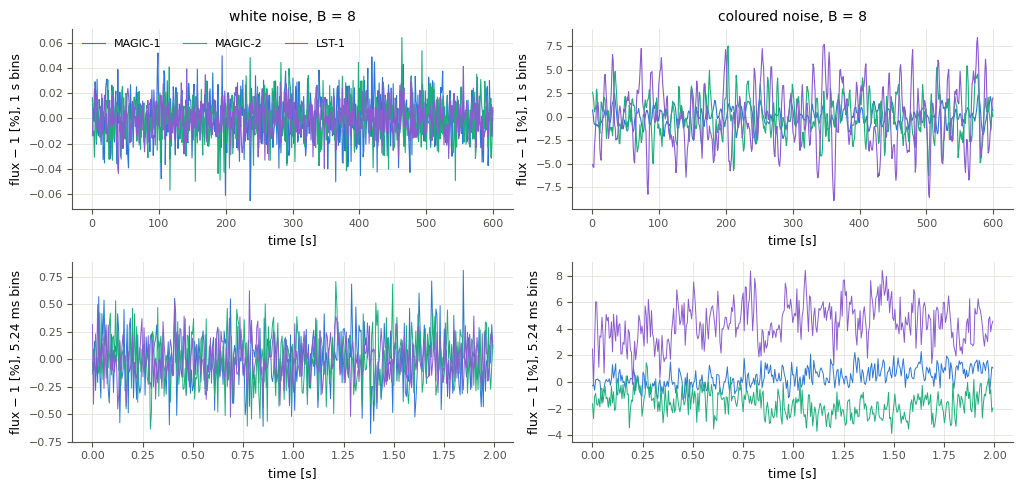

In [12]:
refs_kw = refs if profiles is not None else None
RUNS = {noise: sy.synthetic_runs(list(MAGS), cfg, noise=noise, references=refs_kw, n_runs=N_RUNS_PER_MAG, run_s=RUN_S, seed=SEED)
        for noise in NOISE_MODELS}
ALL_RUNS = [run for noise in NOISE_MODELS for run in RUNS[noise]]
MAG_OF = {(n.name, o.name): o.mag_B for n, o, _ in ALL_RUNS}
print(f"{len(ALL_RUNS)} synthetic runs of {RUN_S:g} s:", ", ".join(f"{n.name}/{o.name}" for n, o, _ in ALL_RUNS))

demo = {noise: next(run for run in RUNS[noise] if run[1].mag_B == MAG_MID) for noise in NOISE_MODELS}
fig, axes = plt.subplots(2, len(NOISE_MODELS), figsize=(5.2 * len(NOISE_MODELS), 5.0), squeeze=False)
for j, noise in enumerate(NOISE_MODELS):
    night, obs, group = demo[noise]
    for ch in ("C", "A", "B"):
        lc = obs.lightcurve(ch)
        k = int(round(1.0 / (lc.time[1] - lc.time[0])))
        n1 = len(lc.signal) // k * k
        axes[0, j].plot(lc.time[:n1].reshape(-1, k).mean(axis=1) - lc.time[0], 100 * (lc.signal[:n1].reshape(-1, k).mean(axis=1) - 1),
                        color=TEL_COLOR[ch], lw=0.8, label=TEL_NAME[ch])
        b = bin_lightcurve(lc, cfg.bin_samples)
        sel = (b.time - b.time[0] > 100) & (b.time - b.time[0] < 102)
        axes[1, j].plot(b.time[sel] - b.time[sel][0], 100 * (b.signal[sel] - 1), color=TEL_COLOR[ch], lw=0.7)
    for i in (0, 1):
        style(axes[i, j])
    axes[0, j].set_title(f"{noise} noise, B = {MAG_MID:g}")
    axes[0, j].set_xlabel("time [s]")
    axes[1, j].set_xlabel("time [s]")
    axes[0, j].set_ylabel("flux − 1 [%], 1 s bins")
    axes[1, j].set_ylabel("flux − 1 [%], 5.24 ms bins")
    obs.release()
axes[0, 0].legend(frameon=False, fontsize=8, ncol=3)
finish(fig, "08_synthetic_lightcurves")

Check that the generated noise has the PSD it was meant to have (solid: Welch PSD of the generated, binned light curve;
dashed: the target `ms.noise_psd`).

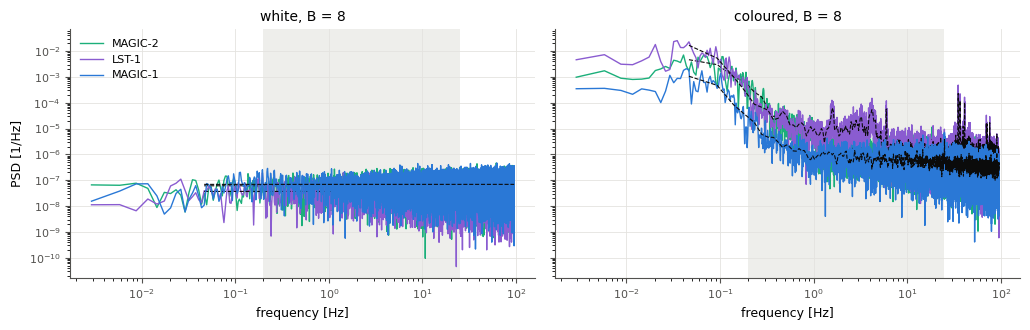

In [13]:
from kbo_occultation.analysis.spectra import lightcurve_psd

fig, axes = plt.subplots(1, len(NOISE_MODELS), figsize=(5.2 * len(NOISE_MODELS), 3.4), sharey=True, squeeze=False)
for ax, noise in zip(axes[0], NOISE_MODELS):
    night, obs, group = demo[noise]
    style(ax)
    ax.axvspan(*SIGNAL_BAND_HZ, color=GRID, alpha=0.6, lw=0)
    star = ms.observed_target(obs, observed_star_mas(obs))
    for p in group:
        f, s = lightcurve_psd(bin_lightcurve(obs.lightcurve(p.channel), cfg.bin_samples))
        ax.plot(f[1:], s[1:], color=TEL_COLOR[p.channel], lw=1.0, label=TEL_NAME[p.channel])
        ax.plot(p.freq[1:], ms.noise_psd(p, star, cfg)[1:], color=INK, ls="--", lw=0.8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{noise}, B = {MAG_MID:g}")
    ax.set_xlabel("frequency [Hz]")
    obs.release()
axes[0, 0].set_ylabel("PSD [1/Hz]")
axes[0, 0].legend(frameon=False, fontsize=8)
finish(fig, "09_synthetic_psd")

### 3d. The noise correction

Before the search each light curve goes through a linear correction. The default is **whitening**: multiply the
spectrum by $G(f)=\sqrt{\min(1,\,S_\mathrm{white}/S(f))}$, where $S_\mathrm{white}$ is the median PSD at high
frequency, so the low-frequency excess is pushed down to the white level. For white noise $G\approx1$, so nothing
changes; for coloured noise the 0.1-few Hz part is attenuated, which also deforms the template (the search uses the
template *as the correction reshapes it*, `noise_removal.reshaped_templates`). The alternatives (`butter_<fc>` high-pass
filters, `raw`) are in `ms.correction_gain`.

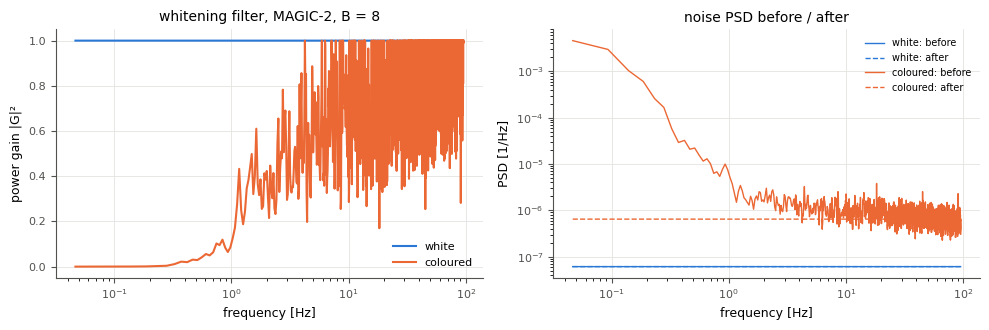

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
style(axes[0]); style(axes[1])
for noise in NOISE_MODELS:
    night, obs, group = demo[noise]
    p = next(q for q in group if q.channel == "A")
    star = ms.observed_target(obs, observed_star_mas(obs))
    psd = ms.noise_psd(p, star, cfg)
    g = ms.correction_gain("whitened", p.freq, psd, p.fs)
    axes[0].plot(p.freq[1:], g[1:] ** 2, color=NOISE_COLOR[noise], label=noise)
    axes[1].plot(p.freq[1:], psd[1:], color=NOISE_COLOR[noise], lw=1.0, label=f"{noise}: before")
    axes[1].plot(p.freq[1:], psd[1:] * g[1:] ** 2, color=NOISE_COLOR[noise], lw=1.0, ls="--", label=f"{noise}: after")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("frequency [Hz]")
axes[0].set_ylabel("power gain |G|²")
axes[0].set_title(f"whitening filter, MAGIC-2, B = {MAG_MID:g}")
axes[1].set_yscale("log")
axes[1].set_ylabel("PSD [1/Hz]")
axes[1].set_title("noise PSD before / after")
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False, fontsize=7)
finish(fig, "10_whitening")

## 4. The matched-filter search on one run

The search (`analysis.mimic.search_lightcurve`, the same code that scans the real data) does, per telescope:

1. correct the light curve (here whitening) and bin it to 5.24 ms;
2. subtract a rolling-median baseline (20 template durations);
3. slide every template of the bank over it, and normalise the correlation by the **rolling robust scatter of the filter
   output itself** (`normalization="empirical"`), so the SNR of pure noise has σ ≈ 1 even if the noise is red;
4. keep the peaks above an SNR floor (3), the best template at each time.

Each template is first reshaped the way the correction reshapes an event: injected into a flat record, corrected, and
the correction of the flat record subtracted. For white noise nothing changes; for coloured noise whitening removes the
low-frequency part of the dip.

demo run: synthetic-coloured/B8_0, bank radii [50.0, 100.0, 300.0, 1000.0] m, template duration 0.80 s


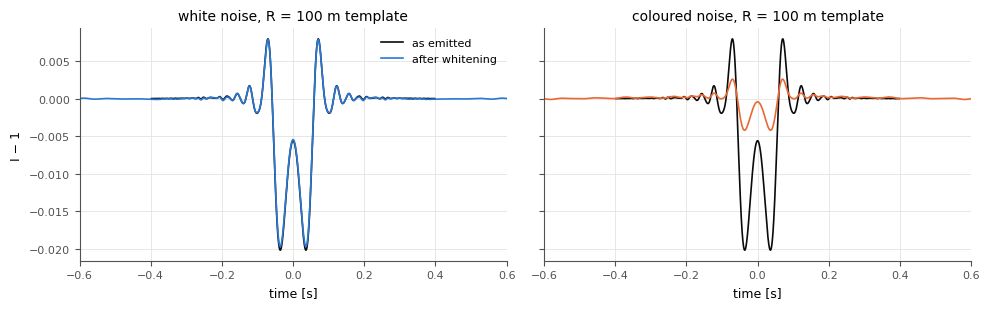

In [15]:
DEMO_NOISE = NOISE_MODELS[-1]
night, obs, group = demo[DEMO_NOISE]
star = ms.observed_target(obs, observed_star_mas(obs))
v_bank = shadow_velocity_opposition(ccfg.mimic.distance_au + EARTH_SEMIMAJOR_AXIS_AU)
bank_raw = star_bank(ccfg.mimic, obs, v_bank)                  # {R: (t, I)}, the search bank of this star
dur = _template_duration(bank_raw)
print(f"demo run: {night.name}/{obs.name}, bank radii {list(bank_raw)} m, template duration {dur:.2f} s")

fig, axes = plt.subplots(1, len(NOISE_MODELS), figsize=(5.0 * len(NOISE_MODELS), 3.2), sharey=True, squeeze=False)
for ax, noise in zip(axes[0], NOISE_MODELS):
    nt, ob, gr = demo[noise]
    lc = ob.lightcurve("A")
    meth = build_methods(lc, None, "m2", ["whitened"])["whitened"]
    reshaped = reshaped_templates(lc, meth, bank_raw, v_bank, ccfg)
    style(ax)
    t_raw, i_raw = bank_raw[100.0]
    t_res, i_res = reshaped[100.0]
    ax.plot(t_raw, i_raw - 1, color=INK, lw=1.2, label="as emitted")
    ax.plot(t_res, i_res - 1, color=NOISE_COLOR[noise], lw=1.2, label="after whitening")
    ax.set_xlim(-0.6, 0.6)
    ax.set_title(f"{noise} noise, R = 100 m template")
    ax.set_xlabel("time [s]")
    ob.release()
axes[0, 0].set_ylabel("I − 1")
axes[0, 0].legend(frameon=False, fontsize=8)
finish(fig, "11_reshaped_template")

Now one event of $R = 150$ m is injected at the middle of the run into all three telescopes (the shadow reaches them
a few ms apart, `shadow_offsets_s`; the pattern goes through each telescope's own response), the light curves are
corrected and searched. Left: the 5 ms light curve around the event. Middle: the SNR trace of the best template over
the whole run. Right: zoom on the event, one line per bank template.

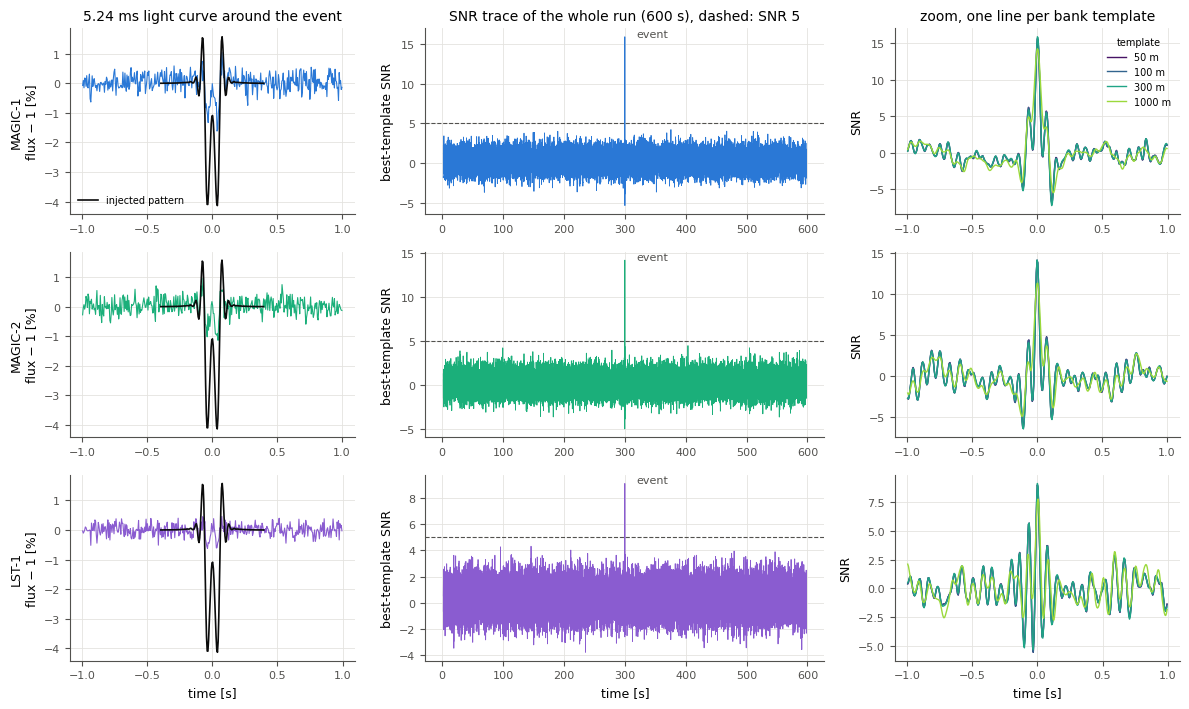

MAGIC-1 :  65 candidates above SNR 3; best SNR 15.9 at -0.0 ms from the event, template R = 300 m
MAGIC-2 :  61 candidates above SNR 3; best SNR 14.2 at -1.9 ms from the event, template R = 300 m
LST-1   :  81 candidates above SNR 3; best SNR 9.1 at -0.8 ms from the event, template R = 300 m


In [16]:
DEMO_R = 150.0
patterns = {k: ms.injection_patterns(star, cfg, INSTR[k], [DEMO_R])[DEMO_R] for k in ("MAGIC", "LST")}
t_start = obs.time_span()[0]
t0 = t_start + 0.5 * RUN_S
offsets = shadow_offsets_s(None, ["C", "A", "B"], V_SHADOW, np.random.default_rng(3))
demo_out = {}
for p in group:
    ch = p.channel
    lc = obs.lightcurve(ch)
    method = build_methods(lc, None, "", ["whitened"])["whitened"]
    bank_m = reshaped_templates(lc, method, bank_raw, v_bank, ccfg)
    x, i_pat = patterns["LST" if ch == "B" else "MAGIC"]
    inj = inject_occultation(lc.time, lc.signal, x, i_pat, V_SHADOW, t0_s=t0 + offsets[ch])
    injected = bin_lightcurve(method.correct(LightCurve(lc.time, inj.injected_signal, meta=dict(lc.meta))), cfg.bin_samples)
    clean = bin_lightcurve(method.correct(lc), cfg.bin_samples)
    traces = {}
    for radius, (tt, ti) in bank_m.items():
        base, sig = compute_baseline_and_sigma(injected.time, injected.signal, dur)
        traces[radius] = sliding_matched_filter_snr(injected.time, injected.signal, tt, ti, baseline=base, sigma=sig,
                                                    normalization="empirical")
    base, sig = compute_baseline_and_sigma(clean.time, clean.signal, dur)
    noise_trace = sliding_matched_filter_snr(clean.time, clean.signal, *bank_m[100.0], baseline=base, sigma=sig,
                                             normalization="empirical")
    demo_out[ch] = dict(injected=injected, clean=clean, traces=traces, noise_trace=noise_trace, bank_m=bank_m, t_event=t0 + offsets[ch])
    obs.release()

fig, axes = plt.subplots(3, 3, figsize=(12, 7.2), gridspec_kw={"width_ratios": [1, 1.4, 1]})
for row, ch in zip(axes, ("C", "A", "B")):
    d = demo_out[ch]
    te = d["t_event"]
    inj = d["injected"]
    for ax in row:
        style(ax)
    sel = np.abs(inj.time - te) < 1.0
    level = np.median(inj.signal)
    row[0].plot(inj.time[sel] - te, 100 * (inj.signal[sel] / level - 1), color=TEL_COLOR[ch], lw=0.8)
    pattern = family_of(star, cfg, [DEMO_R])[DEMO_R]
    t_pat = -cfg.x_half_m / V_SHADOW + (np.arange(len(pattern)) + 0.5) * cfg.bin_dt_s
    row[0].plot(t_pat, 100 * pattern, color=INK, lw=1.2, label="injected pattern")
    row[0].set_ylabel(f"{TEL_NAME[ch]}\nflux − 1 [%]")
    best = np.max([tr.snr for tr in d["traces"].values()], axis=0)
    tt = next(iter(d["traces"].values())).time
    row[1].plot(tt - t_start, best, color=TEL_COLOR[ch], lw=0.6)
    row[1].axhline(5.0, color=MUTED, ls="--", lw=0.8)
    row[1].annotate("event", (te - t_start, best.max()), xytext=(8, 0), textcoords="offset points", fontsize=8, color=MUTED)
    row[1].set_ylabel("best-template SNR")
    for (radius, tr), c in zip(d["traces"].items(), plt.cm.viridis(np.linspace(0.05, 0.85, 4))):
        s = np.abs(tr.time - te) < 1.0
        row[2].plot(tr.time[s] - te, tr.snr[s], color=c, lw=1.0, label=f"{radius:g} m")
    row[2].set_ylabel("SNR")
for ax in axes[-1]:
    ax.set_xlabel("time [s]")
axes[0, 0].set_title("5.24 ms light curve around the event")
axes[0, 0].legend(frameon=False, fontsize=7, loc="lower left")
axes[0, 1].set_title(f"SNR trace of the whole run ({RUN_S:g} s), dashed: SNR 5")
axes[0, 2].set_title("zoom, one line per bank template")
axes[0, 2].legend(frameon=False, fontsize=7, title="template", title_fontsize=7)
finish(fig, "12_matched_filter_demo")

from kbo_occultation.analysis.mimic import search_lightcurve
for ch in ("C", "A", "B"):
    d = demo_out[ch]
    rows, _, calib = search_lightcurve(d["injected"], d["bank_m"], 3.0, dur, ccfg.mimic.sigma_window_s)
    top = max(rows, key=lambda r: r["snr"])
    print(f"{TEL_NAME[ch]:8s}: {len(rows):3d} candidates above SNR 3; best SNR {top['snr']:.1f} at "
          f"{(top['time_s'] - d['t_event']) * 1e3:+.1f} ms from the event, template R = {top['radius_m']:g} m")

**Is the normalisation right?** The SNR trace of the *uninjected* light curve should be a unit Gaussian: if its σ is 1,
a threshold of SNR $s$ means the same false-alarm rate whatever the noise colour or level. The histogram below uses the
$R = 100$ m template on the three telescopes.

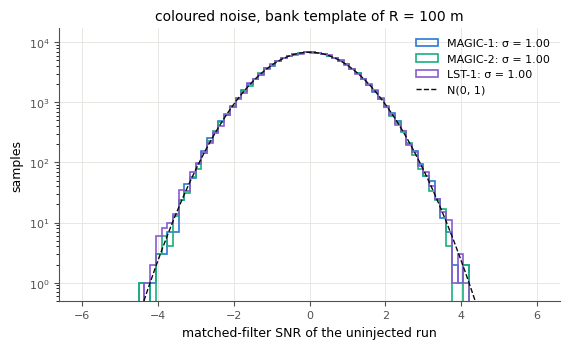

In [17]:
fig, ax = plt.subplots(figsize=(5.8, 3.6))
style(ax)
bins = np.linspace(-6, 6, 81)
for ch in ("C", "A", "B"):
    z = demo_out[ch]["noise_trace"].snr
    ax.hist(z, bins=bins, histtype="step", color=TEL_COLOR[ch], lw=1.2, label=f"{TEL_NAME[ch]}: σ = {np.std(z):.2f}")
xs = np.linspace(-6, 6, 200)
ax.plot(xs, len(z) * (bins[1] - bins[0]) * np.exp(-0.5 * xs ** 2) / np.sqrt(2 * np.pi), color=INK, ls="--", lw=1, label="N(0, 1)")
ax.set_yscale("log")
ax.set_ylim(0.5, None)
ax.set_xlabel("matched-filter SNR of the uninjected run")
ax.set_ylabel("samples")
ax.set_title(f"{DEMO_NOISE} noise, bank template of R = 100 m")
ax.legend(frameon=False, fontsize=8)
finish(fig, "13_snr_trace_histogram")

## 5. Injections, false alarms and detection thresholds

**What is run.** For every synthetic run and noise correction, `ms.calibrate_run`:

1. searches the *uninjected* run blindly with the bank: its candidates (SNR > 3) are the false alarms, and their number per
   hour gives the single-telescope rate $r(s)$ above SNR $s$;
2. injects the same star-only event (radius $R$, impact parameter 0, random time, each telescope's own response and shadow
   delay) into all three channels, `N_TRIALS` times for each radius in `RADII`, and searches each injected window blindly;
3. records the best SNR of the bank within 50 ms of the event (`peak_snr`) and every candidate near it.

It is the same code as the calibration against real runs (`examples/studies/min_size_calibration.py`); only the light
curves are generated. Results are cached per run in `outputs/notebooks/synthetic_upper_limits/trials/`.

In [18]:
import zlib

BANK = None                                           # None: calibrate_run builds each star's own bank (mimic.star_bank)
if not PER_STAR_BANK:
    from kbo_occultation.analysis.mimic import search_templates
    BANK = search_templates(ccfg.mimic, v_bank)
ref_key = "" if profiles is None else "_ref%08x" % zlib.crc32("|".join(f"{g['A'].night}/{g['A'].observation}" for g in refs).encode())
TAG = (f"t{N_TRIALS}_r{RADII[0]:g}-{RADII[-1]:g}x{len(RADII)}_s{RUN_S:g}_seed{SEED}" + ("" if PER_STAR_BANK else "_fixedbank") + ref_key)

parts = {k: [] for k in ("trials", "cands", "calib", "full")}
t_all = time.time()
for night, obs, group in ALL_RUNS:
    pattern_cache = {}
    for corr in CORRECTIONS:
        stem = OUT / "trials" / f"{night.name}_{obs.name}_{corr}_{TAG}"
        paths = {k: Path(f"{stem}_{k}.csv") for k in parts}
        if all(p.exists() for p in paths.values()):
            frames, status = {k: read_csv_or_empty(p) for k, p in paths.items()}, "cached"
        else:
            t = time.time()
            full_rows = []
            tr, ca, ka = ms.calibrate_run(night, obs, group, cfg, ccfg, corr, list(RADII), sf_mode="measured",
                                          n_trials=N_TRIALS, seed=SEED, bank=BANK, patterns=pattern_cache,
                                          full_candidates=full_rows)
            frames = {"trials": tr, "cands": ca, "calib": ka, "full": pd.DataFrame(full_rows)}
            for k, df in frames.items():
                df.to_csv(paths[k], index=False)
            status = f"{time.time() - t:.0f} s"
        for k, df in frames.items():
            parts[k].append(df)
        print(f"{night.name:20s} {obs.name:6s} {corr:9s} {status}")
    obs.release()
trials, cands, run_calib, full = (cat(parts[k]) for k in ("trials", "cands", "calib", "full"))
for df in (cands, run_calib, full):
    if len(df):
        df["mag_B"] = [MAG_OF[(n, o)] for n, o in zip(df["night"], df["observation"])]
print(f"{len(trials)} injected searches, {len(full)} false-alarm candidates in {run_calib.groupby('night')['live_s'].sum().sum() / 3600:.2f} telescope-hours "
      f"({time.time() - t_all:.0f} s)")
print("\nSNR trace of the uninjected runs (σ and MAD-σ ≈ 1 means the empirical normalisation is right):")
print(run_calib.groupby(["night", "correction", "channel"])[["snr_std", "snr_mad_sigma", "n_candidates"]].mean().round(2).to_string())

synthetic-white      B7_0   whitened  cached
synthetic-white      B8_0   whitened  cached
synthetic-white      B9_0   whitened  cached
synthetic-coloured   B7_0   whitened  cached
synthetic-coloured   B8_0   whitened  cached
synthetic-coloured   B9_0   whitened  cached
2160 injected searches, 1068 false-alarm candidates in 3.00 telescope-hours (0 s)

SNR trace of the uninjected runs (σ and MAD-σ ≈ 1 means the empirical normalisation is right):
                                       snr_std  snr_mad_sigma  n_candidates
night              correction channel                                      
synthetic-coloured whitened   A           1.00            1.0         63.67
                              B           0.99            1.0         74.00
                              C           1.00            1.0         64.00
synthetic-white    whitened   A           1.00            1.0         51.67
                              B           1.00            1.0         48.00
                    

### Thresholds from the false-alarm rate

The detection threshold is not chosen by hand: it is the SNR at which the **accidental rate** equals the target false-alarm
rate (FAR). `sy.rate_curves_from_candidates` turns each telescope's blind-search candidates into a rate $r_j(s)$ (empirical
up to the 20th-largest candidate, an exponential tail beyond it, `ms.RateCurve`). Requiring $k$ of 3 telescopes within
the coincidence window $\tau$ (`cfg.tolerance_s()`: the shadow's travel time across the array, a few ms, plus half a
template duration for the timing jitter of the matched filter, which dominates) multiplies the rates:

$$r_{2/3}(s) = \sum_{i<j} r_i(s)\,r_j(s)\;2\tau .$$

A 2-of-3 coincidence tolerates a much lower per-telescope threshold than a single telescope at the same FAR; that is
why combining the array pays. **Caveat:** the false-alarm tails come from the few telescope-hours of synthetic runs, so
the thresholds at low FAR are extrapolated (the table marks them). The package does the same with the real data, where
the tail comes from about one hour.

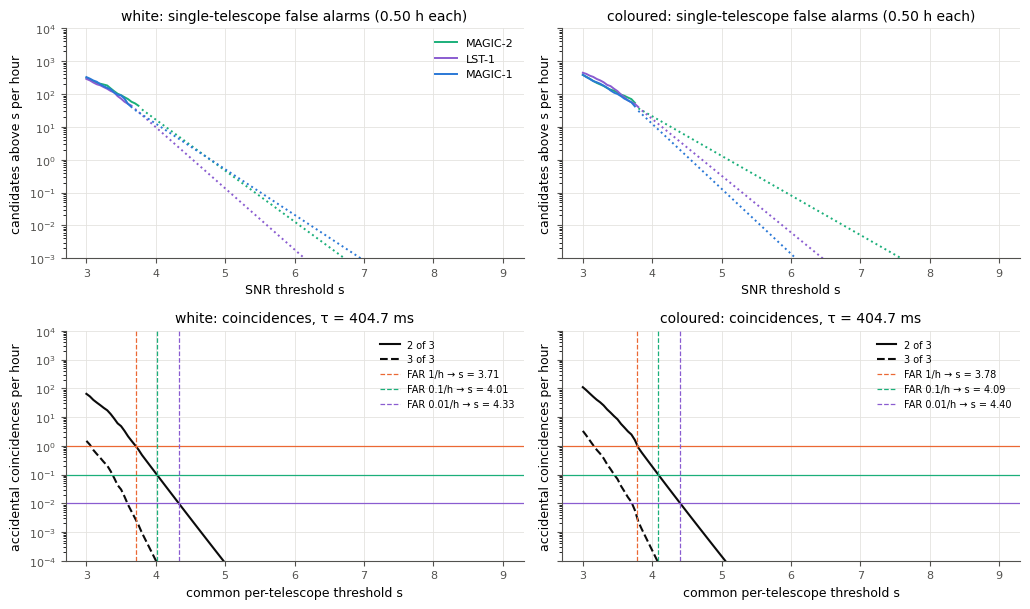

per-telescope SNR thresholds (whitened);  * extrapolated beyond the measured tail,  ° at the SNR floor (the FAR is only an upper bound)
config                          2of3  3of3      A      B      C
night              far_per_hr                                  
synthetic-coloured 0.01        4.40*  3.71  6.76*  5.88*  5.56*
                   0.10        4.09*  3.45  5.93*  5.30*  5.06*
                   1.00        3.78*  3.16  5.10*  4.72*  4.55*
synthetic-white    0.01        4.33*  3.59  6.07*  5.60*  6.23*
                   0.10        4.01*  3.38  5.43*  5.07*  5.51*
                   1.00        3.71*  3.06  4.79*  4.53*  4.79*


In [19]:
curves = sy.rate_curves_from_candidates(full, run_calib)         # {(night, correction): {channel: RateCurve}}
thresholds = cat([ms.thresholds_table(cv, TOL, FARS).assign(night=n, correction=c) for (n, c), cv in curves.items()])
HEAD_CORR = CORRECTIONS[0]

s_grid = np.linspace(3.0, 9.0, 121)
fig, axes = plt.subplots(2, len(NOISE_MODELS), figsize=(5.2 * len(NOISE_MODELS), 6.2), squeeze=False, sharey="row")
for j, noise in enumerate(NOISE_MODELS):
    cv = curves[(f"synthetic-{noise}", HEAD_CORR)]
    ax = style(axes[0, j])
    for ch, curve in cv.items():
        r = np.array([curve.rate(s) for s in s_grid])
        ext = np.array([curve.extrapolated(s) for s in s_grid])
        ax.plot(s_grid[~ext], r[~ext], color=TEL_COLOR[ch], lw=1.4, label=f"{TEL_NAME[ch]}")
        ax.plot(s_grid[ext], r[ext], color=TEL_COLOR[ch], lw=1.4, ls=":")
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 1e4)
    ax.set_title(f"{noise}: single-telescope false alarms ({curve.hours:.2f} h each)")
    ax.set_xlabel("SNR threshold s")
    ax.set_ylabel("candidates above s per hour")
    if j == 0:
        ax.legend(frameon=False, fontsize=8)
    ax = style(axes[1, j])
    for k, ls in ((2, "-"), (3, "--")):
        if k <= len(cv):
            ax.plot(s_grid, [ms.coincidence_rate(cv, s, TOL, k) for s in s_grid], color=INK, ls=ls, label=f"{k} of {len(cv)}")
    for far, c in zip(FARS, ("#eb6834", "#1baf7a", "#8a5cd0")):
        ax.axhline(far, color=c, lw=0.9)
        row = thresholds[(thresholds["night"] == f"synthetic-{noise}") & (thresholds["correction"] == HEAD_CORR)
                         & (thresholds["config"] == f"{MIN_NTEL}of{len(cv)}") & (thresholds["far_per_hr"] == far)]
        ax.axvline(float(row["threshold"].iloc[0]), color=c, lw=0.9, ls="--", label=f"FAR {far:g}/h → s = {float(row['threshold'].iloc[0]):.2f}")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1e4)
    ax.set_xlabel("common per-telescope threshold s")
    ax.set_ylabel("accidental coincidences per hour")
    ax.set_title(f"{noise}: coincidences, τ = {TOL * 1e3:.1f} ms")
    ax.legend(frameon=False, fontsize=7)
finish(fig, "14_false_alarms")

show = thresholds[thresholds["correction"] == HEAD_CORR].copy()
show["threshold"] = [f"{t:.2f}" + ("*" if e else "") + ("°" if f else "") for t, e, f in zip(show["threshold"], show["thr_extrapolated"], show["thr_at_floor"])]
print(f"per-telescope SNR thresholds ({HEAD_CORR});  * extrapolated beyond the measured tail,  ° at the SNR floor (the FAR is only an upper bound)")
print(show.pivot_table(index=["night", "far_per_hr"], columns="config", values="threshold", aggfunc="first").to_string())

## 6. Injection and recovery

**Predicted SNR.** Without injections, the package predicts the SNR an event will have: the expected matched-filter SNR of
the template in the noise PSD *after the correction*, $\mathrm{SNR}=|GT|/\sigma_\mathrm{mf}(GT,|G|^2S)$
(`ms.expected_snr`). It comes in two flavours: with the perfectly matched template (`matched`, the upper bound) and with
the best template of the search bank (`bank`, what the search really achieves). On stationary Gaussian noise, which is
what these runs are, the bank prediction should reproduce the injections to a few per cent.

**Predicted efficiency.** Each telescope's SNR is Gaussian around its expectation (σ = 1 in these units); the event is
detected if at least $k$ telescopes exceed the thresholds above (a Poisson-binomial, `ms.detection_probability`).

In [20]:
def predict_snr(runs, corrections, radii, use_bank):
    # Expected peak SNR of every run, correction, channel and radius (the same table as ms.predicted_snr, which
    # recomputes the templates for every run): the SNR of the event in the noise of the run after the correction,
    # found with its own template (use_bank = False, the upper bound) or with the best template of the search bank.
    rows = []
    for night, obs, group in runs:
        star = ms.observed_target(obs, observed_star_mas(obs))
        fam = family_of(star, cfg, radii)
        bank = (bank_own[obs.mag_B] if PER_STAR_BANK else bank_fixed) if use_bank else None
        for corr in corrections:
            cfg_c = replace(cfg, correction=corr, snr_scale=1.0)
            for p in group:
                f = ms.snr_evaluator(star, p, cfg_c)
                for r in radii:
                    v = max(f(t, signal=fam[float(r)]) for t in bank.values()) if use_bank else f(fam[float(r)])
                    rows.append({"night": night.name, "observation": obs.name, "correction": corr, "channel": p.channel,
                                 "telescope": p.telescope, "radius_m": float(r), "snr_pred": float(v), "block": 0})
    return pd.DataFrame(rows)


snr_pred = {}
for label in ("matched", "bank"):
    path = OUT / "trials" / f"predicted_snr_{label}_{TAG}.csv"
    if path.exists():
        snr_pred[label] = pd.read_csv(path)
    else:
        t = time.time()
        snr_pred[label] = predict_snr(ALL_RUNS, CORRECTIONS, list(RADII), use_bank=(label == "bank"))
        snr_pred[label].to_csv(path, index=False)
        print(f"predicted SNR ({label}): {time.time() - t:.0f} s")

eff_parts = []
for (night, corr), g in trials.groupby(["night", "correction"]):
    thr = thresholds[(thresholds["night"] == night) & (thresholds["correction"] == corr)]
    sel_c = cands[(cands["night"] == night) & (cands["correction"] == corr)] if len(cands) else cands
    meas = ms.measured_efficiency(g, sel_c, thr, TOL)
    for label, df in snr_pred.items():
        sp = df[(df["night"] == night) & (df["correction"] == corr)]
        pred = ms.predicted_efficiency(sp, thr).rename(columns={"eff_pred": f"eff_pred_{label}"})
        meas = meas.merge(pred[["night", "observation", "correction", "radius_m", "config", "far_per_hr", f"eff_pred_{label}"]],
                          on=["night", "observation", "correction", "radius_m", "config", "far_per_hr"], how="left")
    eff_parts.append(meas)
eff = cat(eff_parts)
eff["mag_B"] = [MAG_OF[(n, o)] for n, o in zip(eff["night"], eff["observation"])]
pooled = (eff.groupby(["night", "correction", "mag_B", "radius_m", "config", "far_per_hr"])
          .agg(hits=("hits", "sum"), n=("n", "sum"), threshold=("threshold", "first"),
               eff_pred_matched=("eff_pred_matched", "mean"), eff_pred_bank=("eff_pred_bank", "mean")).reset_index())
pooled["eff"] = pooled["hits"] / pooled["n"]
pooled["eff_err"] = binomial_err(pooled["hits"].to_numpy(float), pooled["n"].to_numpy(float))
print(f"{len(pooled)} (noise, B, radius, configuration, FAR) efficiency points; {int(pooled['n'].max())} injections each at most")

720 (noise, B, radius, configuration, FAR) efficiency points; 15 injections each at most


**Peak SNR of the recovered events** (median over the injections, band: 16-84 %) against the prediction. The peak SNR
is above the prediction only where the noise adds to a weak signal (low SNR), so only the points above SNR ≈ 5 are
informative.

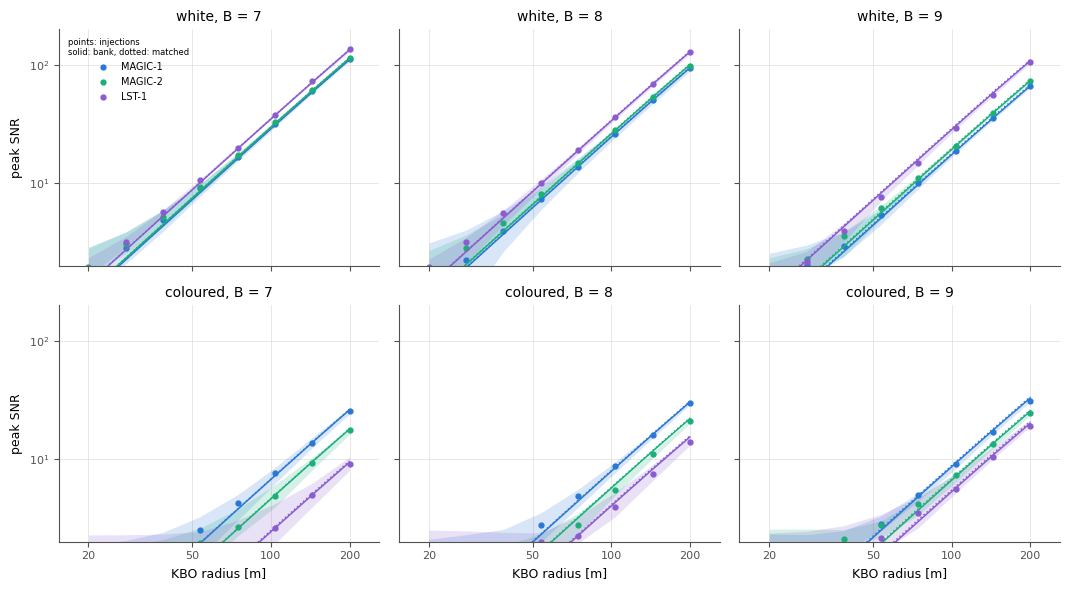

In [21]:
tp = trials[trials["correction"] == HEAD_CORR]
fig, axes = plt.subplots(len(NOISE_MODELS), len(MAGS), figsize=(3.6 * len(MAGS), 3.0 * len(NOISE_MODELS)), squeeze=False, sharex=True, sharey=True)
for i, noise in enumerate(NOISE_MODELS):
    for j, mag in enumerate(MAGS):
        ax = style(axes[i, j])
        sel = tp[(tp["night"] == f"synthetic-{noise}") & tp["observation"].str.startswith(f"B{mag:g}_")]
        pr = {k: v[(v["night"] == f"synthetic-{noise}") & (v["correction"] == HEAD_CORR) & v["observation"].str.startswith(f"B{mag:g}_")]
              for k, v in snr_pred.items()}
        for ch in ("C", "A", "B"):
            g = sel[sel["channel"] == ch].groupby("radius_m")["peak_snr"]
            r = g.median().index.to_numpy()
            ax.fill_between(r, g.quantile(0.16), g.quantile(0.84), color=TEL_COLOR[ch], alpha=0.18, lw=0)
            ax.plot(r, g.median(), "o", ms=3.5, color=TEL_COLOR[ch], label=TEL_NAME[ch])
            for label, ls in (("bank", "-"), ("matched", ":")):
                p = pr[label][pr[label]["channel"] == ch].groupby("radius_m")["snr_pred"].mean()
                ax.plot(p.index, p.values, color=TEL_COLOR[ch], lw=1.1, ls=ls)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(RADII[0] / 1.3, RADII[-1] * 1.3)
        ax.set_xticks([t for t in (20, 50, 100, 200) if RADII[0] / 1.3 <= t <= RADII[-1] * 1.3])
        ax.set_xticklabels([str(t) for t in (20, 50, 100, 200) if RADII[0] / 1.3 <= t <= RADII[-1] * 1.3])
        ax.minorticks_off()
        ax.set_ylim(2, 200)
        ax.set_title(f"{noise}, B = {mag:g}")
        if i == len(NOISE_MODELS) - 1:
            ax.set_xlabel("KBO radius [m]")
        if j == 0:
            ax.set_ylabel("peak SNR")
axes[0, 0].legend(frameon=False, fontsize=7, title="points: injections\nsolid: bank, dotted: matched", title_fontsize=6)
finish(fig, "15_peak_snr")

**Efficiency** against radius for each telescope alone and for the array (2 of 3 in black, at the headline FAR), with
the binomial error of the `N_TRIALS` × runs injections and the bank prediction as a line. At the same threshold the
array is more efficient than any telescope alone, and LST-1 is the least efficient of the three here: the larger mirror
is more than compensated by its larger excess noise in the real-noise profiles (it has no such disadvantage in white
noise).

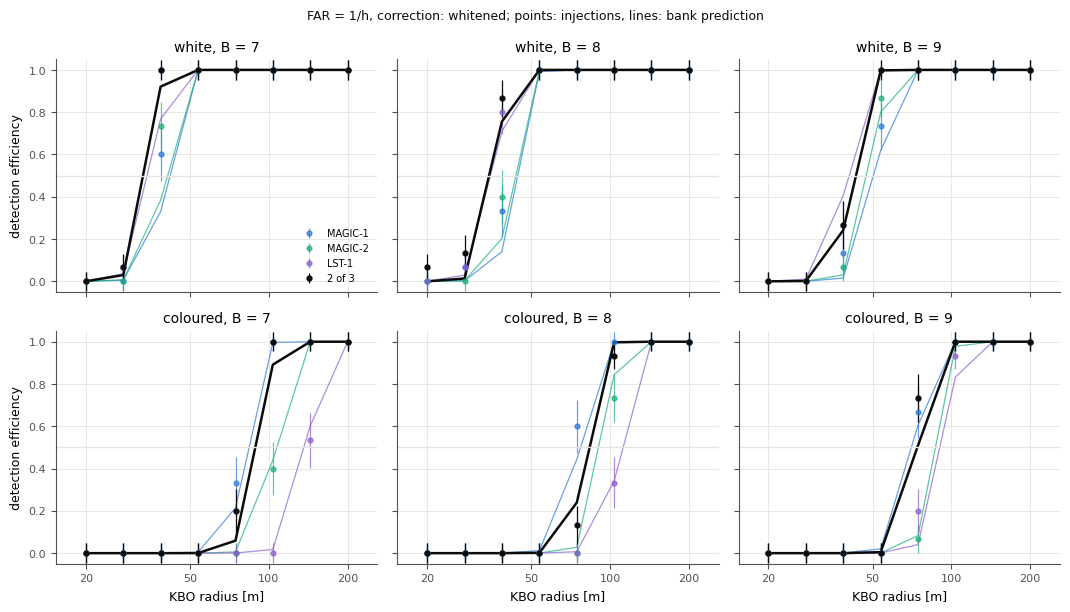

In [22]:
HEAD_FAR = FARS[0]
sub = pooled[(pooled["correction"] == HEAD_CORR) & (pooled["far_per_hr"] == HEAD_FAR)]
fig, axes = plt.subplots(len(NOISE_MODELS), len(MAGS), figsize=(3.6 * len(MAGS), 3.1 * len(NOISE_MODELS)), squeeze=False, sharex=True, sharey=True)
for i, noise in enumerate(NOISE_MODELS):
    for j, mag in enumerate(MAGS):
        ax = style(axes[i, j])
        for config in ("C", "A", "B", f"{MIN_NTEL}of3"):
            g = sub[(sub["night"] == f"synthetic-{noise}") & (sub["mag_B"] == mag) & (sub["config"] == config)].sort_values("radius_m")
            if g.empty:
                continue
            c = INK if "of" in config else TEL_COLOR[config]
            lab = f"{MIN_NTEL} of 3" if "of" in config else TEL_NAME[config]
            ax.errorbar(g["radius_m"], g["eff"], g["eff_err"], fmt="o", ms=3.5, color=c, elinewidth=0.9, alpha=1.0 if "of" in config else 0.7, label=lab)
            ax.plot(g["radius_m"], g["eff_pred_bank"], color=c, lw=1.8 if "of" in config else 0.9, alpha=1.0 if "of" in config else 0.7)
        ax.axhline(0.5, color=GRID, lw=1)
        ax.set_xscale("log")
        ax.set_xlim(RADII[0] / 1.3, RADII[-1] * 1.3)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xticks([t for t in (20, 50, 100, 200) if RADII[0] / 1.2 <= t <= RADII[-1] * 1.2])
        ax.set_xticklabels([str(t) for t in (20, 50, 100, 200) if RADII[0] / 1.2 <= t <= RADII[-1] * 1.2])
        ax.minorticks_off()
        ax.set_title(f"{noise}, B = {mag:g}")
        if i == len(NOISE_MODELS) - 1:
            ax.set_xlabel("KBO radius [m]")
        if j == 0:
            ax.set_ylabel("detection efficiency")
axes[0, 0].legend(frameon=False, fontsize=7, loc="lower right")
fig.suptitle(f"FAR = {HEAD_FAR:g}/h, correction: {HEAD_CORR}; points: injections, lines: bank prediction", fontsize=9, color=INK)
finish(fig, "16_efficiency")

**Is the predictor right?** For each run and telescope, the ratio (measured peak SNR) / (predicted SNR) is fitted over
the radii where the SNR is well measured (5-50). A scale of 1 against the **bank** prediction means that the predictor is
exact for noise that satisfies its assumptions (Gaussian, stationary), and a scale below 1 against the **matched** one is
the cost of the search bank. On real runs the scale is not 1 (`ms.SNR_CALIBRATION_STATIONARY`, printed below): the extra
offset is due to the intermittent, non-Gaussian noise of the real data, not to the search.

In [23]:
rows = []
for label, sp in snr_pred.items():
    per_run, _ = ms.fit_snr_calibration(trials, sp, run_calib)
    rows.append(per_run.assign(prediction=label))
scale = cat(rows)
tab = (scale.groupby(["night", "correction", "prediction", "kind"]).agg(scale=("scale", "median"), lo=("scale", "min"), hi=("scale", "max"),
                                                                     scatter=("scatter", "median"), n=("scale", "size")).round(2))
print("measured / predicted peak SNR (median over run-channels, with the range):")
print(tab.to_string())
print("\nfor comparison, the real runs, stationary noise:", {k: v[0] for k, v in ms.SNR_CALIBRATION_STATIONARY.items()})

measured / predicted peak SNR (median over run-channels, with the range):
                                                scale    lo    hi  scatter  n
night              correction prediction kind                                
synthetic-coloured whitened   bank       LST     0.97  0.91  0.99     1.28  3
                                         MAGIC   0.99  0.95  1.00     0.87  6
                              matched    LST     0.94  0.89  0.96     1.28  3
                                         MAGIC   0.97  0.93  0.99     0.87  6
synthetic-white    whitened   bank       LST     1.02  0.94  1.03     0.85  3
                                         MAGIC   1.02  1.00  1.05     0.95  6
                              matched    LST     1.01  0.92  1.02     0.85  3
                                         MAGIC   1.00  0.99  1.04     0.95  6

for comparison, the real runs, stationary noise: {'whitened': 0.912, 'raw': 1.539, 'butter_1': 1.082}


## 7. The minimum detectable size

**R50** is the radius at which the array detects half of the events (here with at least `MIN_NTEL` of 3 telescopes in
coincidence, at the headline FAR, for a central chord). `ms.efficiency_r50` interpolates it (in log R) from the efficiency
curves of section 6: from the injections (`meas`), from the prediction with the matched template (`matched`), and from
the prediction with the search bank (`bank`). With `N_TRIALS` injections per point the measured R50 has an uncertainty of
~10-20 % (and is read off a coarse radius grid); the predicted one is smooth.

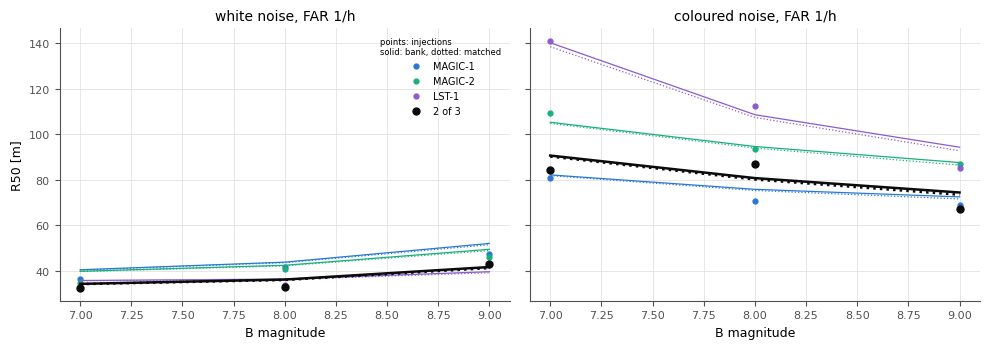

R50 [m] of 2 of 3, correction whitened:  injections / search-bank prediction / matched-template prediction
FAR 1/h
mag_B                        7.0           8.0           9.0
night                                                       
synthetic-coloured  84 / 91 / 90  87 / 81 / 80  67 / 74 / 73
synthetic-white     32 / 34 / 34  33 / 36 / 36  43 / 42 / 41
FAR 0.1/h
mag_B                        7.0           8.0           9.0
night                                                       
synthetic-coloured  89 / 94 / 94  88 / 84 / 83  69 / 77 / 76
synthetic-white     33 / 36 / 36  33 / 38 / 38  44 / 43 / 43
FAR 0.01/h
mag_B                        7.0           8.0           9.0
night                                                       
synthetic-coloured  90 / 98 / 97  90 / 87 / 87  81 / 80 / 79
synthetic-white     33 / 37 / 37  34 / 39 / 39  46 / 45 / 45


In [24]:
by = ["night", "correction", "mag_B", "config", "far_per_hr"]
r50 = ms.efficiency_r50(pooled, "eff", by).rename(columns={"r50_m": "r50_meas", "status": "status_meas"})

# The predicted SNR is a smooth, nearly power-law function of R, while the efficiency rises from 0 to 1 within a
# factor ~2 in R. The prediction is therefore interpolated (log-log) on a fine radius grid before the probability
# and R50 are computed; the injections stay on their own coarse grid.
FINE = np.geomspace(RADII[0], RADII[-1], 200)


def refine(sp):
    keys = ["night", "observation", "correction", "channel", "telescope"]
    out = []
    for key, g in sp.groupby(keys):
        g = g.sort_values("radius_m")
        v = np.exp(np.interp(np.log(FINE), np.log(g["radius_m"]), np.log(np.maximum(g["snr_pred"], 1e-6))))
        out.append(pd.DataFrame({**dict(zip(keys, key)), "radius_m": FINE, "snr_pred": v, "block": 0}))
    return pd.concat(out, ignore_index=True)


for label, sp in snr_pred.items():
    spf = refine(sp)
    parts_f = []
    for (night, corr), _ in trials.groupby(["night", "correction"]):
        thr = thresholds[(thresholds["night"] == night) & (thresholds["correction"] == corr)]
        pf = ms.predicted_efficiency(spf[(spf["night"] == night) & (spf["correction"] == corr)], thr)
        pf["mag_B"] = [MAG_OF[(night, o)] for o in pf["observation"]]
        parts_f.append(pf)
    pf = (cat(parts_f).groupby(by[:3] + ["radius_m", "config", "far_per_hr"], as_index=False)["eff_pred"].mean())
    part = ms.efficiency_r50(pf, "eff_pred", by).rename(columns={"r50_m": f"r50_{label}", "status": f"status_{label}"})
    r50 = r50.merge(part, on=by)
r50["ratio_bank"] = r50["r50_bank"] / r50["r50_meas"]

fig, axes = plt.subplots(1, len(NOISE_MODELS), figsize=(5.0 * len(NOISE_MODELS), 3.6), squeeze=False, sharey=True)
for ax, noise in zip(axes[0], NOISE_MODELS):
    style(ax)
    sub = r50[(r50["night"] == f"synthetic-{noise}") & (r50["correction"] == HEAD_CORR) & (r50["far_per_hr"] == HEAD_FAR)]
    for config in ("C", "A", "B", f"{MIN_NTEL}of3"):
        g = sub[sub["config"] == config].sort_values("mag_B")
        c = INK if "of" in config else TEL_COLOR[config]
        lab = f"{MIN_NTEL} of 3" if "of" in config else TEL_NAME[config]
        w = 1.8 if "of" in config else 0.9
        ax.plot(g["mag_B"], g["r50_meas"], "o", color=c, ms=5 if "of" in config else 3.5, label=lab)
        ax.plot(g["mag_B"], g["r50_bank"], "-", color=c, lw=w)
        ax.plot(g["mag_B"], g["r50_matched"], ":", color=c, lw=w)
    ax.set_xlabel("B magnitude")
    ax.set_title(f"{noise} noise, FAR {HEAD_FAR:g}/h")
axes[0, 0].set_ylabel("R50 [m]")
axes[0, 0].legend(frameon=False, fontsize=7, title="points: injections\nsolid: bank, dotted: matched", title_fontsize=6)
finish(fig, "17_r50_vs_mag")

head = r50[(r50["config"] == f"{MIN_NTEL}of3") & (r50["correction"] == HEAD_CORR)]
print(f"R50 [m] of {MIN_NTEL} of 3, correction {HEAD_CORR}:  injections / search-bank prediction / matched-template prediction")
for far in FARS:
    h = head[head["far_per_hr"] == far]
    print(f"FAR {far:g}/h")
    print(h.assign(R50=[f"{m:.0f} / {b:.0f} / {t:.0f}" for m, b, t in zip(h["r50_meas"], h["r50_bank"], h["r50_matched"])])
          .pivot_table(index="night", columns="mag_B", values="R50", aggfunc="first").to_string())
bad = r50[(r50["status_meas"] != "ok")]
if len(bad):
    print(f"\n{len(bad)} configurations never reach 50 % (above the radius grid) or already do at the smallest radius: they have no measured R50")

### Impact parameter: R50 is for a central chord

The R50 above is for an event that passes through the centre of the shadow (impact parameter $b = 0$), the brightest
case. A real survey sees every $b$ equally likely, and the *effective cross-section* is the **detection width**

$$W(R) = 2\int_0^\infty P(R,b)\,\mathrm{d}b ,$$

with $P(R,b)$ the probability of detecting an event at impact parameter $b$. It is compared with the shadow width of Nihei et
al. (2007), $H(R) = 2\big[(\sqrt3F)^{3/2}+R^{3/2}\big]^{2/3} + 2r_\star$ ($F$ the Fresnel scale, $r_\star$ the projected star
radius): $H \to 2\sqrt3F+2r_\star \approx 5$ km for $R \ll F$ and $\to 2R$ for large $R$. `ms.width_signals` computes the
event at 16 impact parameters per radius, `ms.detection_width` finds $P(R,b)$ from the SNR it would have, searched with the
$b=0$ template, as the search does.

(The wiggles of $W/H$ in the figure below are the sampling of $P(R,b)$ at 16 impact parameters across the Fresnel fringes, about
±15 %; the limits of section 10 inherit them.) Three things come out of it. At the R50 radius $W/H$ is only ~10 %, since only the central chords are detected. $W/H$ grows
quickly with $R$ and **exceeds 1** for large $R$ because the diffraction fringes remain detectable outside the geometric
shadow. And it is $W$, not $H$, that sets the rate of detected events. This is the efficiency that the upper limits of
section 10 use.

cells whose probability at the largest impact parameter is above 2 % (W cut short): 0


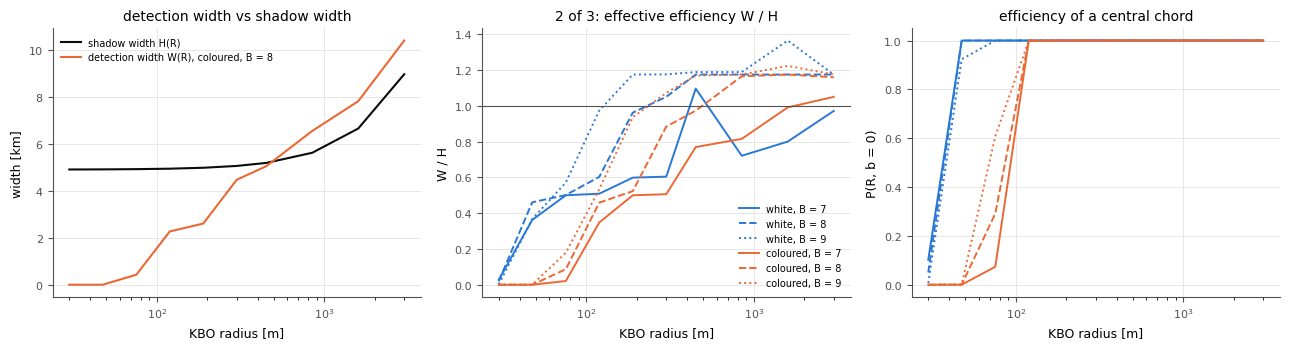

white    B = 7: at R50 = 34 m, W/H = 0.13
white    B = 8: at R50 = 36 m, W/H = 0.20
white    B = 9: at R50 = 42 m, W/H = 0.26
coloured B = 7: at R50 = 91 m, W/H = 0.15
coloured B = 8: at R50 = 81 m, W/H = 0.14
coloured B = 9: at R50 = 74 m, W/H = 0.17


In [25]:
WIDTH_RADII = np.round(np.concatenate([np.geomspace(30.0, 300.0, 6 if FAST else 9),       # dense around R50
                                        np.geomspace(450.0, 3000.0, 4 if FAST else 6)]), 1)  # up to the literature's sizes
cfg_w = replace(cfg, radii_m=WIDTH_RADII)
width_path = OUT / "trials" / f"detection_width_{TAG}_w{len(WIDTH_RADII)}.csv"
if width_path.exists():
    widths = pd.read_csv(width_path)
else:
    t_w = time.time()
    rows = []
    for mag in MAGS:
        star = star_of[mag]
        fam = family_of(star, cfg, WIDTH_RADII)
        sig = ms.width_signals(star, cfg_w, INSTR["MAGIC"])        # LST-1 has the same shape (section 2)
        templates, signals = {"MAGIC": fam, "LST": fam}, {"MAGIC": sig, "LST": sig}
        for noise in NOISE_MODELS:
            night, obs, group = next(run for run in RUNS[noise] if run[1].mag_B == mag)
            cv = curves[(night.name, HEAD_CORR)]
            for label, sel, k in [(p.channel, [p], 1) for p in group] + [(f"{MIN_NTEL}of3", group, MIN_NTEL)]:
                thr, _ = ms.array_threshold(cv, tuple(p.channel for p in sel), k, HEAD_FAR, TOL)
                w = ms.detection_width(star, sel, cfg_w, templates, signals, k=k, threshold=thr)
                rows.append(w.assign(mag_B=mag, noise=noise, config=label, threshold=thr))
        print(f"B = {mag:g}: {time.time() - t_w:.0f} s")
    widths = pd.concat(rows, ignore_index=True)
    widths.to_csv(width_path, index=False)
print("cells whose probability at the largest impact parameter is above 2 % (W cut short):", int((widths["p_tail"] > 0.02).sum()))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax in axes:
    style(ax)
for noise in NOISE_MODELS:
    for mag, ls in zip(MAGS, ("-", "--", ":")):
        g = widths[(widths["noise"] == noise) & (widths["mag_B"] == mag) & (widths["config"] == f"{MIN_NTEL}of3")].sort_values("radius_m")
        axes[1].plot(g["radius_m"], g["eff_eff"], ls, color=NOISE_COLOR[noise], lw=1.4, label=f"{noise}, B = {mag:g}")
        axes[2].plot(g["radius_m"], g["p_b0"], ls, color=NOISE_COLOR[noise], lw=1.4)
g8 = widths[(widths["noise"] == NOISE_MODELS[-1]) & (widths["mag_B"] == MAG_MID) & (widths["config"] == f"{MIN_NTEL}of3")].sort_values("radius_m")
axes[0].plot(g8["radius_m"], g8["h_m"] / 1e3, color=INK, label="shadow width H(R)")
axes[0].plot(g8["radius_m"], g8["width_m"] / 1e3, color=NOISE_COLOR[NOISE_MODELS[-1]], label=f"detection width W(R), {NOISE_MODELS[-1]}, B = {MAG_MID:g}")
axes[0].set_ylabel("width [km]")
axes[0].set_title("detection width vs shadow width")
axes[1].axhline(1.0, color=MUTED, lw=0.8)
axes[1].set_ylabel("W / H")
axes[1].set_title(f"{MIN_NTEL} of 3: effective efficiency W / H")
axes[1].legend(frameon=False, fontsize=7)
axes[2].set_ylabel("P(R, b = 0)")
axes[2].set_title("efficiency of a central chord")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("KBO radius [m]")
axes[0].legend(frameon=False, fontsize=7)
finish(fig, "18_detection_width")

r50_h = r50[(r50["config"] == f"{MIN_NTEL}of3") & (r50["correction"] == HEAD_CORR) & (r50["far_per_hr"] == HEAD_FAR)]
for noise in NOISE_MODELS:
    for mag in MAGS:
        r = r50_h[(r50_h["night"] == f"synthetic-{noise}") & (r50_h["mag_B"] == mag)]["r50_bank"]
        g = widths[(widths["noise"] == noise) & (widths["mag_B"] == mag) & (widths["config"] == f"{MIN_NTEL}of3")]
        if len(r) and np.isfinite(r.iloc[0]):
            print(f"{noise:8s} B = {mag:g}: at R50 = {r.iloc[0]:.0f} m, W/H = {np.interp(np.log(r.iloc[0]), np.log(g['radius_m']), g['eff_eff']):.2f}")

## 8. What changes the result

Almost everything the user can choose moves R50. The prediction of section 6, which reproduces the injections, is
fast enough to scan them: `predict_r50` below is what `ms.min_size_table` does for one star (the expected SNR of each
telescope after the correction, the thresholds of section 5, the Poisson-binomial probability of $k$ of $n$ above them,
and `ms.r50`). It changes **one thing at a time** from a baseline: the star of magnitude `MAG_MID` (B = 8 by default), whitening, 2 of 3 telescopes, FAR 1/h,
search with the star's own bank, the noise model of the last entry of `NOISE_MODELS`.

| Group | Choice | What it changes |
|---|---|---|
| Detection | FAR, $k$ of $n$ (a single telescope, 3 of 3) | the SNR threshold, i.e. how many false alarms you accept |
| Noise | theory only / white / coloured, `excess_scaling`, real-data calibration | the noise level in the signal band |
| Instrument | LST-1 focus, search bank | photons from the star, how much of the SNR the search keeps |
| Observation | KBO distance, airmass | shadow size and speed, photon counts and scintillation |
| Correction | `whitened`, `butter_1`, `raw` (only with `FAST = False`) | how much of the 0.1-few Hz noise is removed, and at what cost to the signal |

The optical filter is not offered: `Instrument(filter_type=...)` supports it, but the noise model behind these
predictions (`ms.model_budget`) builds its instrument without one, so the knob would change only the template.

In [26]:
BASE_MAG = MAG_MID
BASE_NOISE = NOISE_MODELS[-1]
BASE_BANK = "own" if PER_STAR_BANK else "fixed"
KNOB_RADII = np.round(np.geomspace(20.0, 400.0, 11 if FAST else 16), 2)
FINE_K = np.geomspace(KNOB_RADII[0], KNOB_RADII[-1], 300)        # the SNR is interpolated (log-log) onto this grid

_BANKS = {("own", mag, cfg.heliocentric_au, cfg.x_half_m): bank_own[mag] for mag in MAGS}
_BANKS[("fixed", None, cfg.heliocentric_au, cfg.x_half_m)] = bank_fixed


def bank_for(kind, mag, cfg_v):
    if kind is None:
        return None
    key = (kind, mag if kind == "own" else None, cfg_v.heliocentric_au, cfg_v.x_half_m)
    if key not in _BANKS:
        _BANKS[key] = ms.bank_deltas(cfg_v, star=star_of[mag]) if kind == "own" else ms.bank_deltas(cfg_v)
    return _BANKS[key]


def group_of(noise, mag):
    return next(g for n, o, g in RUNS[noise] if o.mag_B == mag)


def predict_r50(mag, *, noise=BASE_NOISE, cfg_v=None, k=MIN_NTEL, far=HEAD_FAR, channels=("A", "B", "C"), theory=False,
                focus=1.0, bank=BASE_BANK, corr=HEAD_CORR, airmass=None):
    # R50 [m] (nan: not reached below 400 m) predicted for a star of magnitude ``mag`` and the choices given
    cfg_v = replace(cfg_v or cfg, radii_m=KNOB_RADII, correction=corr)
    star = star_of[mag]
    fam = family_of(star, cfg_v, KNOB_RADII)
    bk = bank_for(bank, mag, cfg_v)
    cv = curves[(f"synthetic-{noise}", corr)]
    thr, _ = ms.array_threshold(cv, tuple(channels), k, far, cfg_v.tolerance_s())
    snr = {}
    for p in group_of(noise, mag):
        if p.channel not in channels:
            continue
        if airmass is not None:
            p = replace(p, airmass=airmass)
        f = ms.snr_evaluator(star, p, cfg_v, theory_only=theory, focus_gain=focus)
        v = np.array([max(f(t, signal=fam[float(r)]) for t in bk.values()) if bk else f(fam[float(r)]) for r in KNOB_RADII])
        snr[p.channel] = np.exp(np.interp(np.log(FINE_K), np.log(KNOB_RADII), np.log(np.maximum(v, 1e-6))))
    return ms.r50(FINE_K, ms.detection_probability(snr, thr, k, cfg_v.snr_scatter))[0]


knobs = [("Detection", "baseline", {})]
knobs += [("Detection", f"FAR {far:g}/h", dict(far=far)) for far in FARS[1:]]
knobs += [("Detection", "3 of 3 telescopes", dict(k=3))]
knobs += [("Detection", f"{TEL_NAME[ch]} alone", dict(k=1, channels=(ch,))) for ch in ("C", "A", "B")]
knobs += [("Noise", "theory only (no excess, no whitening)", dict(theory=True))]
if len(NOISE_MODELS) > 1:
    knobs += [("Noise", f"{n} noise", dict(noise=n)) for n in NOISE_MODELS if n != BASE_NOISE]
if BASE_NOISE == "coloured":
    knobs += [("Noise", "excess fixed in total-signal units", dict(cfg_v=replace(cfg, excess_scaling="total")))]
sc, scat = ms.SNR_CALIBRATION_STATIONARY["whitened"]
knobs += [("Noise", f"real-data SNR calibration (×{sc:.2f}, σ {scat:.2f})", dict(cfg_v=replace(cfg, snr_scale=sc, snr_scatter=scat)))]
knobs += [("Instrument", "LST-1 at infinity focus (×2 light)", dict(focus=2.0)),
          ("Instrument", "matched template (ideal bank)", dict(bank=None))]
if PER_STAR_BANK:
    knobs += [("Instrument", "fixed 0.03 mas search bank", dict(bank="fixed"))]
for d in (30.0, 50.0):
    knobs += [("Observation", f"KBO at {d:g} AU", dict(cfg_v=replace(cfg, distance_au=d, heliocentric_au=d + 1.0)))]
knobs += [("Observation", f"airmass {a:g}", dict(airmass=a)) for a in (1.0, 1.6)]
knobs += [("Correction", f"correction {c}", dict(corr=c)) for c in CORRECTIONS[1:]]

t = time.time()
knob_tab = pd.DataFrame([{"group": g, "choice": name, "r50_m": predict_r50(BASE_MAG, **kw)} for g, name, kw in knobs])
base_r50 = float(knob_tab.loc[knob_tab["choice"] == "baseline", "r50_m"].iloc[0])
knob_tab["change_%"] = 100.0 * (knob_tab["r50_m"] / base_r50 - 1.0)
print(f"baseline: B = {BASE_MAG:g}, {BASE_NOISE} noise, {HEAD_CORR}, {MIN_NTEL} of 3, FAR {HEAD_FAR:g}/h:  R50 = {base_r50:.0f} m   ({time.time() - t:.0f} s)")
print(knob_tab.round(1).to_string(index=False))

baseline: B = 8, coloured noise, whitened, 2 of 3, FAR 1/h:  R50 = 81 m   (100 s)
      group                                    choice  r50_m  change_%
  Detection                                  baseline   80.7       0.0
  Detection                                 FAR 0.1/h   84.0       4.0
  Detection                                FAR 0.01/h   87.3       8.1
  Detection                         3 of 3 telescopes   89.9      11.4
  Detection                             MAGIC-1 alone   75.8      -6.1
  Detection                             MAGIC-2 alone   94.6      17.2
  Detection                               LST-1 alone  108.5      34.5
      Noise     theory only (no excess, no whitening)   36.6     -54.7
      Noise                               white noise   36.2     -55.1
      Noise        excess fixed in total-signal units   96.2      19.2
      Noise real-data SNR calibration (×0.91, σ 1.23)   84.4       4.5
 Instrument        LST-1 at infinity focus (×2 light)   80.7      

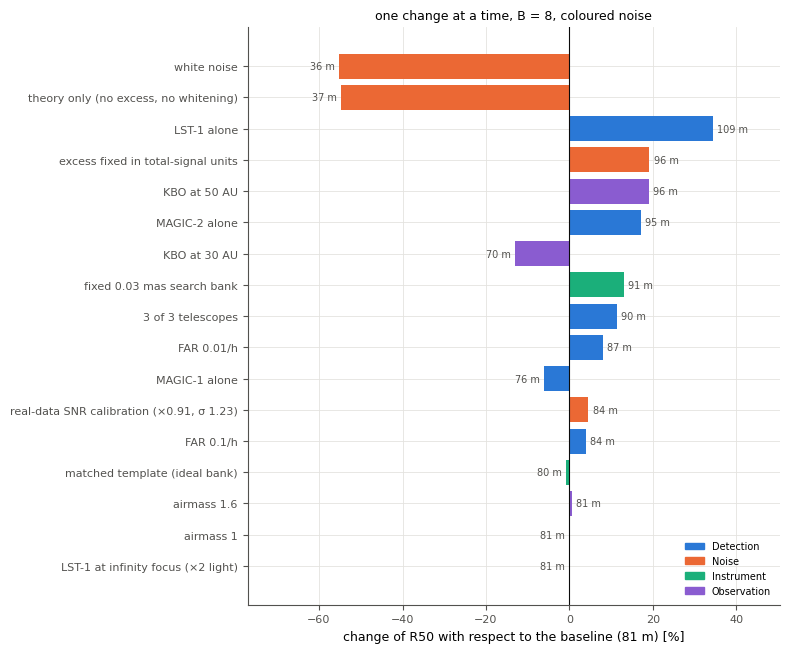

In [27]:
plot = knob_tab[knob_tab["choice"] != "baseline"].copy()
plot["sort"] = plot["change_%"].abs().fillna(1e3)
plot = plot.sort_values("sort")
fig, ax = plt.subplots(figsize=(8.0, 0.32 * len(plot) + 1.2))
style(ax)
colors = {"Detection": "#2a78d6", "Noise": "#eb6834", "Instrument": "#1baf7a", "Observation": "#8a5cd0", "Correction": "#52514e"}
y = np.arange(len(plot))
ax.barh(y, plot["change_%"].fillna(0), color=[colors[g] for g in plot["group"]])
for yi, (_, row) in zip(y, plot.iterrows()):
    label = "not reached below 400 m" if np.isnan(row["r50_m"]) else f"{row['r50_m']:.0f} m"
    ax.text(row["change_%"] + (1 if np.nan_to_num(row["change_%"]) >= 0 else -1), yi, label, va="center", fontsize=7, color=MUTED,
            ha="left" if np.nan_to_num(row["change_%"]) >= 0 else "right")
ax.set_yticks(y)
ax.set_yticklabels(plot["choice"], fontsize=8)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel(f"change of R50 with respect to the baseline ({base_r50:.0f} m) [%]")
ax.set_title(f"one change at a time, B = {BASE_MAG:g}, {BASE_NOISE} noise", fontsize=9)
from matplotlib.patches import Patch
ax.set_xlim(min(plot["change_%"].min(), 0) - 22, max(plot["change_%"].max(), 0) + 16)
ax.legend(handles=[Patch(color=c, label=g) for g, c in colors.items() if g in set(plot["group"])], frameon=False, fontsize=7, loc="lower right")
finish(fig, "19_r50_knobs")

The same scan along the magnitude, for the choices that matter most. R50 falls with B only as long as the noise is
photon-limited; once the correlated excess (which does not shrink with the star's brightness) dominates, a fainter,
smaller star gives sharper fringes but no better SNR.

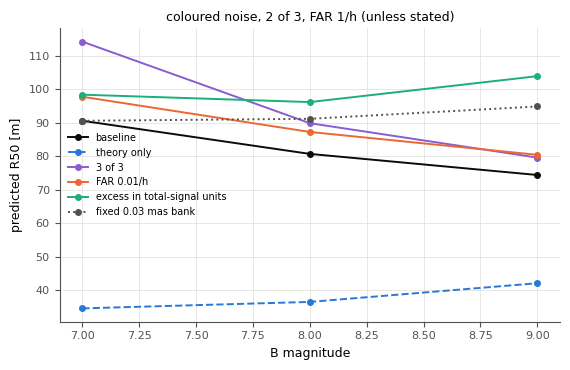

In [28]:
curves_vs_b = [("baseline", {}), ("theory only", dict(theory=True)), ("3 of 3", dict(k=3)), (f"FAR {FARS[-1]:g}/h", dict(far=FARS[-1]))]
if BASE_NOISE == "coloured":
    curves_vs_b += [("excess in total-signal units", dict(cfg_v=replace(cfg, excess_scaling="total")))]
if PER_STAR_BANK:
    curves_vs_b += [("fixed 0.03 mas bank", dict(bank="fixed"))]
fig, ax = plt.subplots(figsize=(5.8, 3.8))
style(ax)
for (name, kw), c, ls in zip(curves_vs_b, ("#0b0b0b", "#2a78d6", "#8a5cd0", "#eb6834", "#1baf7a", "#52514e"), ("-", "--", "-", "-", "-", ":")):
    ax.plot(MAGS, [predict_r50(m, **kw) for m in MAGS], "o", color=c, ls=ls, ms=4, lw=1.4, label=name)
ax.set_xlabel("B magnitude")
ax.set_ylabel("predicted R50 [m]")
ax.set_title(f"{BASE_NOISE} noise, {MIN_NTEL} of 3, FAR {HEAD_FAR:g}/h (unless stated)", fontsize=9)
ax.legend(frameon=False, fontsize=7)
finish(fig, "20_r50_vs_mag_knobs")

## 9. Observing time

How long must the array stare at a star to see one occultation? For a star monitored with a detection width $W$ at shadow
velocity $v$, the rate of detected events by KBOs of diameter $D$ and cumulative sky density $\Sigma(>D)$ is
(Nihei et al. 2007, eq. 8; `rates.event_rate`)

$$\mu = W\, v\, \Sigma(>D)\,\Big(\frac{180^\circ}{\pi d}\Big)^2 .$$

The density follows the broken power law of Nihei et al.: $\Sigma(>D)\propto D^{1-q_s}$ below the break diameter
($D_\mathrm{break}$ = 80 km) and $D^{1-q_L}$ ($q_L = 4.8$) above it. The slope of the small-object distribution is the great
unknown: $q_s = 2$-4 are shown, 4 is the headline. Two views of the same quantity, both with the **detection** width $W(R)$
of section 7 in place of $H(R)$:

* **per size** (`rates.observing_time_per_size`): hours to detect one object of radius $R$ or larger, treating every object as
  if it had exactly that radius, as in a cumulative limit;
* **whole distribution** (`rates.detected_event_rate`): the rate integrated over all sizes, each with its own $W(R)$.

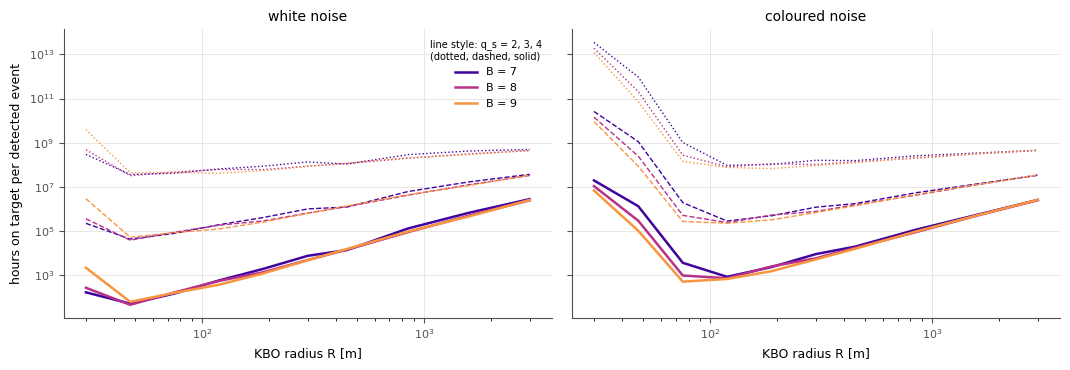

hours on one star per detected event, whole size distribution (2 of 3, FAR 1/h, D_break = 80 km):
                   q_s = 2   q_s = 3  q_s = 4
noise    mag_B                               
coloured 7.0    35144943.0  152335.0    410.0
         8.0    30041226.0  115112.0    278.0
         9.0    26345461.0   86968.0    198.0
white    7.0    18168940.0   24537.0     25.0
         8.0    16310321.0   24087.0     26.0
         9.0    16305182.0   27043.0     34.0


In [29]:
velocity = V_SHADOW * u.m / u.s
distance = (cfg.distance_au * u.au).to(u.m)
two = widths[widths["config"] == f"{MIN_NTEL}of3"]

rows = []
for (noise, mag), g in two.groupby(["noise", "mag_B"]):
    g = g.sort_values("radius_m")
    for q in Q_S:
        per_size = rates.observing_time_per_size(g["radius_m"].to_numpy(), g["width_m"].to_numpy(), velocity, distance, D_BREAK, q).to(u.hr).value
        total = float((1.0 / rates.detected_event_rate(g["radius_m"].to_numpy(), g["width_m"].to_numpy(), velocity, distance, D_BREAK, q)).to(u.hr).value)
        rows += [{"noise": noise, "mag_B": mag, "q_s": q, "radius_m": r, "hours_per_event": h, "hours_whole_distribution": total}
                 for r, h in zip(g["radius_m"], per_size)]
obs_time = pd.DataFrame(rows)

fig, axes = plt.subplots(1, len(NOISE_MODELS), figsize=(5.4 * len(NOISE_MODELS), 3.8), squeeze=False, sharey=True)
for ax, noise in zip(axes[0], NOISE_MODELS):
    style(ax)
    for mag, c in zip(MAGS, plt.cm.plasma(np.linspace(0.1, 0.75, len(MAGS)))):
        for q, ls, lw in zip(Q_S, (":", "--", "-"), (1.0, 1.0, 1.8)):
            g = obs_time[(obs_time["noise"] == noise) & (obs_time["mag_B"] == mag) & (obs_time["q_s"] == q)]
            ok = np.isfinite(g["hours_per_event"]) & (g["hours_per_event"] > 0)
            ax.plot(g["radius_m"][ok], g["hours_per_event"][ok], color=c, ls=ls, lw=lw, label=f"B = {mag:g}" if q == Q_S_HEADLINE else None)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("KBO radius R [m]")
    ax.set_title(f"{noise} noise")
axes[0, 0].set_ylabel("hours on target per detected event")
axes[0, 0].legend(frameon=False, fontsize=8, title="line style: q_s = " + ", ".join(f"{q:g}" for q in Q_S) + "\n(dotted, dashed, solid)", title_fontsize=7)
finish(fig, "21_observing_time")

whole = obs_time.drop_duplicates(["noise", "mag_B", "q_s"]).pivot_table(index=["noise", "mag_B"], columns="q_s", values="hours_whole_distribution")
whole.columns = [f"q_s = {q:g}" for q in whole.columns]
print("hours on one star per detected event, whole size distribution (2 of 3, FAR "
      f"{HEAD_FAR:g}/h, D_break = {D_BREAK_KM:g} km):")
print(whole.round(0).to_string())

The hours are on target, with the three telescopes tracking the same star. A handful of stars of similar magnitude
add up linearly. They are the average over a *uniform* impact parameter (that is the point of using $W$), and they do not
include weather, airmass changes, the Moon or duty cycle. Few objects are detectable at all below ~100 m (the efficiency
vanishes), so the whole-distribution time is dominated by the sizes just above R50 for steep distributions (large $q_s$),
and by the large, rare objects for shallow ones.

## 10. Upper limits on the surface density

A survey that observes stars for a total live time $T$ and sees **no** occultation constrains the cumulative surface density
$N(>r)$ of objects larger than $r$ (TAOS-style; Nihei et al. 2007, Zhang et al. 2008, 2013). Each star sweeps out a solid
angle per radius class

$$\Omega(r) = \frac{H(r)}{d}\,\frac{v\,T}{d},$$

so the expected number of detections is $\mu \ge N(>r)\,\epsilon(r)\,\Omega(r)$, where evaluating everything at $r$ as if all
objects had exactly radius $r$ is the conservative choice for a cumulative limit. For zero events at confidence $c$ the Poisson
upper limit is $\mu_\mathrm{UL} = -\ln(1-c) = 2.996$ (95 %), hence (`upper_limits.cumulative_density_upper_limit`)

$$N(>r) < \frac{\mu_\mathrm{UL}}{\sum_i \epsilon_i(r)\,\Omega_i(r)} .$$

The efficiency $\epsilon(r)$ is the point where the injections of the notebook enter. The consistent choice is
$\epsilon = W/H$ of section 7: then $\epsilon\,H = W$ and a star contributes $W v T/d^2$, i.e. the detection width over all
impact parameters. Using only the efficiency of **central** chords (what the injections measure directly) gives a much
too optimistic limit near R50, shown dotted below for comparison. The `SurveyExposure` must use the same $H$ as the widths
(same wavelength, distance and projected star radius), which is checked below.

The figure reproduces the cumulative-density plot of the rates notebooks: the size distribution of Nihei et al. for three
slopes and published measurements (the x axis is the **radius**; the model, which depends on the diameter, is evaluated at
$D = 2r$).

In [30]:
# ── literature: the values of the rates notebook's plot_cumulative_surface_density ─────────────────────────────────
import kbo_occultation
PACKAGE_DATA = Path(kbo_occultation.__file__).parent / "data"
zhang = np.array([[248.77, 293.53, 355.88, 528.18, 968.89, 2207.32, 4528.09, 7831.52, 14228.28],
                  [3134444930.3, 306356674.8, 33032638.17, 5842667.78, 1536674.68, 334708.08, 119487.74, 62214.46, 60511.62]])
curves_csv = {}
for name in ("Singer", "Fraser"):
    try:
        curves_csv[name] = pd.read_csv(PACKAGE_DATA / f"{name}.csv", sep=";", decimal=",", header=None)
    except FileNotFoundError:
        print(f"{name}.csv not found in {PACKAGE_DATA}: that curve is skipped")


def plot_literature(ax):
    if "Fraser" in curves_csv:
        ax.plot(curves_csv["Fraser"][0], curves_csv["Fraser"][1], linewidth=3, color="y", label="Fraser+ 2014")
    if "Singer" in curves_csv:
        ax.plot(curves_csv["Singer"][0], curves_csv["Singer"][1], linewidth=2.5, color="c", label="Singer+ 2019")
    ax.errorbar(249.20, 10953833, xerr=[597.98 - 249.20], yerr=[[10953833 - 4286308.2], [23368373.6 - 10953833]],
                xlolims=[True], color="C0", fmt=".", capsize=3, label="Schlichting+ 2012")
    ax.errorbar(1305.95, 571054.94, xerr=[[1305.95 - 1163.42], [2196.71 - 1305.95]],
                yerr=[[571054.94 - 89425.38], [1855531.87 - 571054.94]], color="C1", fmt=".", capsize=3, label="Arimatsu+ 2019")
    ax.errorbar(399.48, 14764533.75, xerr=[490.90 - 399.48], yerr=[[14764533.75 - 7150669.59], [54400294.15 - 14764533.75]],
                xlolims=[True], color="C2", fmt=".", capsize=3, label="Liu+ 2015")
    ax.errorbar(349.09, 506513824.4, yerr=[506513824.4 - 191210236.3], uplims=[True], color="red", fmt="-", capsize=3, label="Bianco+ 2009")
    ax.errorbar(503.35, 210113704.58, yerr=[210113704.58 - 79318449.31], uplims=[True], color="red", fmt="-", capsize=3)
    ax.errorbar(zhang[0, :], zhang[1, :], yerr=zhang[1, :] / 3, uplims=True, color="C4", fmt="-", capsize=3, label="Zhang+ 2013")


def nihei_model(ax, radii):
    for q, color in zip(Q_S, ("C0", "C1", "C6")):
        sigma = rates.surface_density(D_BREAK, 2 * radii * u.m, q).value
        ax.plot(radii, sigma, color=color if q != 4 else "C6", lw=1.2, label=f"$q_s = {q:g}$")
    ax.axvline(D_BREAK.to(u.m).value / 2, color="gray", linestyle="--", alpha=0.2)


def survey_exposure(mag, noise, hours, kind="width"):
    g = widths[(widths["noise"] == noise) & (widths["mag_B"] == mag) & (widths["config"] == f"{MIN_NTEL}of3")].sort_values("radius_m")
    eff = EfficiencyCurve(g["radius_m"].to_numpy(), g["eff_eff" if kind == "width" else "p_b0"].to_numpy(), clip=(kind != "width"))
    r_star = star_of[mag].angular_radius_mas * mas_to_rad * cfg.distance_au * AU_m
    return SurveyExposure(f"B{mag:g}", hours * 3600.0, V_SHADOW, cfg.distance_au, eff, star_radius_projected_m=r_star,
                          wavelength_m=ms.WIDTH_WAVELENGTH_M)


# the exposure's H(r) must be the H that W / H was computed with
g0 = widths[(widths["noise"] == BASE_NOISE) & (widths["mag_B"] == BASE_MAG) & (widths["config"] == f"{MIN_NTEL}of3")].sort_values("radius_m")
from kbo_occultation.analysis.upper_limits import exposure_omega_deg2
ex = survey_exposure(BASE_MAG, BASE_NOISE, 1.0)
omega_h = exposure_omega_deg2(ex, g0["radius_m"].to_numpy()) * ex.efficiency(g0["radius_m"].to_numpy())
omega_w = g0["width_m"].to_numpy() / (cfg.distance_au * AU_m) * V_SHADOW * 3600.0 / (cfg.distance_au * AU_m) * (180 / np.pi) ** 2
print("ε·Ω (package) / (W v T / d²):", np.round(omega_h / omega_w, 4))

ε·Ω (package) / (W v T / d²): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


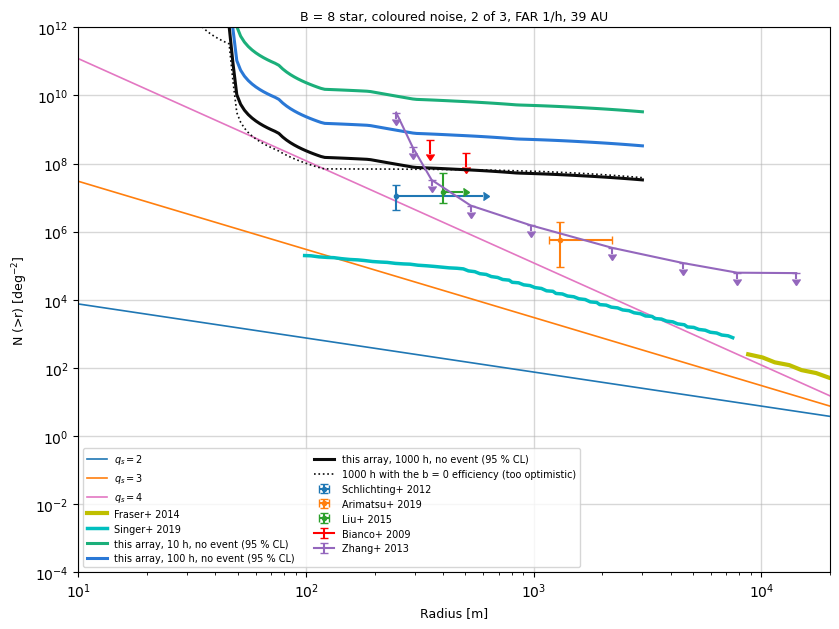

check: N_UL(100 h) / N_UL(1000 h) at 300 m = 10.00  (1/T scaling: 10.00)


In [31]:
UL_MAG, UL_NOISE = BASE_MAG, BASE_NOISE
R_UL = np.geomspace(WIDTH_RADII[0], WIDTH_RADII[-1], 120)
fig, ax = plt.subplots(figsize=(8.5, 6.4))
nihei_model(ax, np.geomspace(10, 2e4, 200))
plot_literature(ax)
for hours, c in zip(SURVEY_HOURS, ("#1baf7a", "#2a78d6", "#0b0b0b")):
    res = cumulative_density_upper_limit([survey_exposure(UL_MAG, UL_NOISE, hours)], R_UL, confidence=0.95)
    ok = np.isfinite(res.n_upper_deg2)
    ax.plot(R_UL[ok], res.n_upper_deg2[ok], color=c, lw=2.2, label=f"this array, {hours:g} h, no event (95 % CL)")
res = cumulative_density_upper_limit([survey_exposure(UL_MAG, UL_NOISE, SURVEY_HOURS[-1], kind="b0")], R_UL)
ok = np.isfinite(res.n_upper_deg2)
ax.plot(R_UL[ok], res.n_upper_deg2[ok], color="#0b0b0b", lw=1.2, ls=":", label=f"{SURVEY_HOURS[-1]:g} h with the b = 0 efficiency (too optimistic)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Radius [m]")
ax.set_ylabel(r"N (>r) [$\mathrm{deg^{-2}}$]")
ax.set_ylim(1e-4, 1e12)
ax.set_xlim(10, 2e4)
ax.grid(True, linewidth=1, alpha=0.5)
ax.legend(loc="lower left", fontsize=7, ncol=2)
ax.set_title(f"B = {UL_MAG:g} star, {UL_NOISE} noise, {MIN_NTEL} of 3, FAR {HEAD_FAR:g}/h, {cfg.distance_au:g} AU", fontsize=9)
finish(fig, "22_upper_limits")
a = cumulative_density_upper_limit([survey_exposure(UL_MAG, UL_NOISE, SURVEY_HOURS[-2])], np.array([300.0])).n_upper_deg2[0]
b = cumulative_density_upper_limit([survey_exposure(UL_MAG, UL_NOISE, SURVEY_HOURS[-1])], np.array([300.0])).n_upper_deg2[0]
print(f"check: N_UL({SURVEY_HOURS[-2]:g} h) / N_UL({SURVEY_HOURS[-1]:g} h) at 300 m = {a / b:.2f}  (1/T scaling: {SURVEY_HOURS[-1] / SURVEY_HOURS[-2]:.2f})")

**How many hours to constrain a model?** Since $N_\mathrm{UL}\propto 1/T$, the time that excludes a given model of the
size distribution at 95 % when no event is seen is $T = N_\mathrm{UL}(1\,\mathrm{h}) / \Sigma_\mathrm{model}(>r)$. It is the
number of hours at which the solid lines above would cross the dashed model curve.

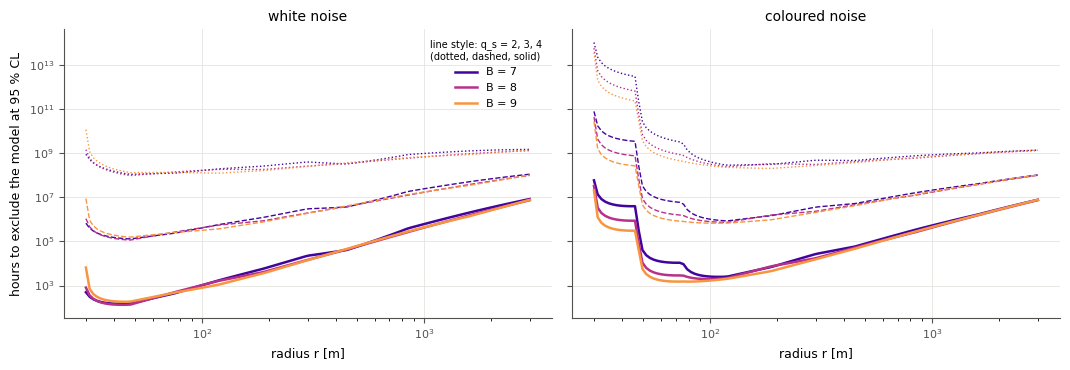

In [32]:
fig, axes = plt.subplots(1, len(NOISE_MODELS), figsize=(5.4 * len(NOISE_MODELS), 3.8), squeeze=False, sharey=True)
need = []
for ax, noise in zip(axes[0], NOISE_MODELS):
    style(ax)
    for mag, c in zip(MAGS, plt.cm.plasma(np.linspace(0.1, 0.75, len(MAGS)))):
        one_hour = cumulative_density_upper_limit([survey_exposure(mag, noise, 1.0)], R_UL).n_upper_deg2
        for q, ls, lw in zip(Q_S, (":", "--", "-"), (1.0, 1.0, 1.8)):
            hours = one_hour / rates.surface_density(D_BREAK, 2 * R_UL * u.m, q).value
            ok = np.isfinite(hours)
            ax.plot(R_UL[ok], hours[ok], color=c, ls=ls, lw=lw, label=f"B = {mag:g}" if q == Q_S_HEADLINE else None)
            need += [{"noise": noise, "mag_B": mag, "q_s": q, "radius_m": r, "hours_95": h} for r, h in zip(R_UL[ok], hours[ok])]
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("radius r [m]")
    ax.set_title(f"{noise} noise")
axes[0, 0].set_ylabel("hours to exclude the model at 95 % CL")
axes[0, 0].legend(frameon=False, fontsize=8, title="line style: q_s = " + ", ".join(f"{q:g}" for q in Q_S) + "\n(dotted, dashed, solid)", title_fontsize=7)
finish(fig, "23_hours_to_exclude")
need = pd.DataFrame(need)

In [33]:
# how many more hours would it take to reach two of the published values? (N_UL scales as 1 / T)
longest = SURVEY_HOURS[-1]
targets = {"Schlichting+ 2012 (r > 250 m)": (250.0, 10953833.0), "Arimatsu+ 2019 (r ≈ 1.3 km)": (1305.95, 571054.94)}
res = cumulative_density_upper_limit([survey_exposure(UL_MAG, UL_NOISE, longest)], np.array([r for r, _ in targets.values()]))
for (name, (r, n_lit)), n_ul in zip(targets.items(), res.n_upper_deg2):
    print(f"{name}: N = {n_lit:.1e} deg⁻².  This array, B = {UL_MAG:g}, {longest:g} h, no event: N(>{r:g} m) < {n_ul:.1e} deg⁻²,"
          f" so about {longest * n_ul / n_lit:.1e} h on target would be needed.")

Schlichting+ 2012 (r > 250 m): N = 1.1e+07 deg⁻².  This array, B = 8, 1000 h, no event: N(>250 m) < 9.5e+07 deg⁻², so about 8.7e+03 h on target would be needed.
Arimatsu+ 2019 (r ≈ 1.3 km): N = 5.7e+05 deg⁻².  This array, B = 8, 1000 h, no event: N(>1305.95 m) < 4.7e+07 deg⁻², so about 8.3e+04 h on target would be needed.


## 11. Summary

The table collects the chain for each noise model and magnitude: the smallest detectable radius (section 7), the effective
efficiency there, the observing time (section 9) and the upper limit that a null survey of `SURVEY_HOURS[-1]` hours would
set at a few radii (section 10).

In [34]:
rows = []
for noise in NOISE_MODELS:
    for mag in MAGS:
        r50_row = r50[(r50["night"] == f"synthetic-{noise}") & (r50["mag_B"] == mag) & (r50["config"] == f"{MIN_NTEL}of3")
                      & (r50["correction"] == HEAD_CORR) & (r50["far_per_hr"] == HEAD_FAR)]
        g = widths[(widths["noise"] == noise) & (widths["mag_B"] == mag) & (widths["config"] == f"{MIN_NTEL}of3")].sort_values("radius_m")
        r50_m = float(r50_row["r50_meas"].iloc[0]) if len(r50_row) else np.nan
        r50_b = float(r50_row["r50_bank"].iloc[0]) if len(r50_row) else np.nan
        hours = obs_time[(obs_time["noise"] == noise) & (obs_time["mag_B"] == mag) & (obs_time["q_s"] == Q_S_HEADLINE)]["hours_whole_distribution"]
        ul = cumulative_density_upper_limit([survey_exposure(mag, noise, SURVEY_HOURS[-1])], np.array([100.0, 200.0, 500.0, 1000.0]))
        rows.append({"noise": noise, "B": mag, "R50 injections [m]": round(r50_m), "R50 predicted [m]": round(r50_b),
                     "W/H at R50": round(float(np.interp(np.log(r50_b), np.log(g["radius_m"]), g["eff_eff"])), 2) if np.isfinite(r50_b) else np.nan,
                     f"h per event (q_s={Q_S_HEADLINE:g})": round(float(hours.iloc[0])) if len(hours) else np.nan,
                     **{f"N(>{r:g} m) [deg⁻²]": f"{n:.1e}" for r, n in zip((100, 200, 500, 1000), ul.n_upper_deg2)}})
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "summary.csv", index=False)
print(f"survey of {SURVEY_HOURS[-1]:g} h on target, no event, 95 % CL; 2 of 3, FAR {HEAD_FAR:g}/h, {cfg.distance_au:g} AU")
print(summary.to_string(index=False))

survey of 1000 h on target, no event, 95 % CL; 2 of 3, FAR 1/h, 39 AU
   noise   B  R50 injections [m]  R50 predicted [m]  W/H at R50  h per event (q_s=4) N(>100 m) [deg⁻²] N(>200 m) [deg⁻²] N(>500 m) [deg⁻²] N(>1000 m) [deg⁻²]
   white 7.0                  32                 34        0.13                   25           1.2e+08           1.0e+08           5.6e+07            7.2e+07
   white 8.0                  33                 36        0.20                   26           1.2e+08           7.1e+07           5.6e+07            5.0e+07
   white 9.0                  43                 42        0.26                   34           9.5e+07           6.4e+07           6.0e+07            5.2e+07
coloured 7.0                  84                 91        0.15                  410           3.0e+08           1.2e+08           7.6e+07            6.3e+07
coloured 8.0                  87                 81        0.14                  278           2.4e+08           1.2e+08           6.6e+07  

### Reading the result, and what it does not include

* **The noise decides the size.** The white rows are the ideal system (photon, scintillation and frame-floor noise only);
  the coloured rows add the correlated excess that real runs show, and R50 is about 1.5-2.5 times larger. Whitening
  recovers part of it, but the 0.1-few Hz noise lies in the signal band, so it cannot be removed without removing signal.
* **R50 is a central-chord number.** The effective efficiency at R50 is only $W/H\approx 0.1$-0.3, and the observing time and
  the upper limits must use $W$.
* **The size distribution dominates the hours.** The slope $q_s$ changes the time per detected event by orders of
  magnitude, much more than any instrument choice of section 8.
* **A limit from one star is weak.** With no event, 1000 hours on one star give limits one to two orders of
  magnitude above the Schlichting and Arimatsu measurements (the cell above gives the hours needed); the limits improve as $1/T$ (more hours, more stars),
  and the last figure shows the time that would exclude each model.

Caveats:

* The noise here is Gaussian, stationary and independent between telescopes. In real runs the noise is intermittent and
  non-Gaussian: the fitted SNR scale is 0.91 for whitening instead of ≈ 1 (`ms.SNR_CALIBRATION_STATIONARY`), and the real
  single-telescope false-alarm rate is 1.6-2.2 times the Gaussian one (README, "How often does noise look like an occultation?"),
  so real thresholds are higher.
* The thresholds come from the blind search of ~3 telescope-hours of synthetic runs and are extrapolated beyond the
  ~20th-largest candidate, in particular for FAR ≤ 0.1/h (marked `*` in section 5).
* The efficiency is for a star-only event at the shadow velocity of the opposition ($\approx 25$ km/s, 39 AU); stars follow a fixed
  surface-brightness law and a 10 000 K spectrum; the detection width samples 16 impact parameters per radius.
* Observing hours are on target. They do not include weather, airmass changes, the Moon or duty cycle, and the limits
  assume one kind of star (a single magnitude).
* Literature values are those of the rates notebook (`plot_cumulative_surface_density`); check them against the papers before
  quoting. The optical filter is not part of the noise model (section 8).

To go from here to real data, see `examples/studies/min_size_calibration.py` and `min_detectable_size.py`, which run the
same chain on the logged runs and write `outputs/min_size/`.